### Choix de la cible

Plusieurs colonnes peuvent servir de cible : `SiteEnergyUse(kBtu)`, `SiteEnergyUseWN(kBtu)` (normalisée météo), `SiteEUI(kBtu/sf)` (par m²) et `TotalGHGEmissions`.

**Choix : `SiteEnergyUse(kBtu)`**, la consommation totale réelle du site.
- Elle est directement interprétable (énergie totale annuelle).
- Elle n'est pas normalisée par la surface : la surface reste donc une feature à apprendre.
- Elle est la plus complète (peu de valeurs manquantes).

Ce choix est conservé pour tout le reste du projet.

### Import des modules

In [77]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [78]:
import warnings
warnings.filterwarnings("ignore")
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from script.preprocessing import make_preprocessor, drop_feature_extremes, split_xy
from script.modeling import make_model, NUMERIC_FEATURES, CATEGORICAL_FEATURES


from script.config import TARGET, MAX_FLOORS, SECOND_TARGET
from script.run_cleaning import clean_dataset, save_datasets
from script.clean_rows import audit_rows
from script.clean_columns import drop_leakage_columns
from script.features import (add_age_features, add_use_features, add_surface_features,
                             add_location_features, build_features, NEW_FEATURES)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Chemin vers le fichier de données fourni
DATA_PATH = "./../data/2016-building-energy-benchmarking.csv"


### Analyse Exploratoire

In [79]:
building_consumption = pd.read_csv(DATA_PATH)
print("Shape brut :", building_consumption.shape)

# Diagnostic des incohérences AVANT nettoyage (ne modifie rien)
display(audit_rows(building_consumption))

# Nettoyage complet (script/run_cleaning.py) : filtres de lignes + traitement des colonnes
df, log = clean_dataset(building_consumption)


Shape brut : (3376, 46)


,nb de lignes
Cible manquante ou <= 0,23
Surface totale <= 0,0
GFA total != Parking + Bâtiment,0
NumberofFloors == 0,16
NumberofFloors > 80,1
NumberofBuildings == 0,92
"YearBuilt hors [1800, 2016]",0
"Surface du plus grand usage > 1,2 x surface totale",86
"Somme des 3 usages > 1,05 x surface totale",503
Plus grand usage manquant,20


Exclusion Multifamily (BuildingType) : 3376 -> 1668 (-1708 lignes, -50.6% vs précédent, 49.4% du brut restant)
Exclusion Multifamily (colonnes d'usage) : 1668 -> 1629 (-39 lignes, -2.3% vs précédent, 48.3% du brut restant)
Conservation des seuls Compliant : 1629 -> 1510 (-119 lignes, -7.3% vs précédent, 44.7% du brut restant)
Suppression cible manquante ou <= 0 : 1510 -> 1510 (-0 lignes, -0.0% vs précédent, 44.7% du brut restant)
NumberofBuildings = 0 -> NaN + BuildingsMissing : 50 lignes concernées (3.3% du jeu), conservées
NumberofFloors invalide -> NaN + FloorsMissing : 16 lignes concernées (1.1% du jeu), conservées
Plus grand usage imputé (usage + surface) : 4 lignes concernées (0.3% du jeu), conservées
Surfaces d'usage incohérentes -> GFAInconsistent : 222 lignes concernées (14.7% du jeu), conservées
Colonnes constantes / vides supprimées : ['DataYear', 'City', 'State', 'DefaultData', 'Comments', 'ComplianceStatus', 'Outlier']
Seuils : 87,829 kBtu / 103,237,656 kBtu -> 12 outliers

In [80]:
# Journal du nettoyage : nombre de lignes et % de perte à chaque étape
display(log.to_frame())
print(log.summary())

# Règles qui modifient ou signalent des lignes SANS les supprimer
display(log.touched_frame())


,étape,avant,après,supprimées,% perdu vs étape précédente,% perdu vs brut,% restant vs brut
0,Exclusion Multifamily (BuildingType),3376,1668,1708,50.59,50.59,49.41
1,Exclusion Multifamily (colonnes d'usage),1668,1629,39,2.34,1.16,48.25
2,Conservation des seuls Compliant,1629,1510,119,7.31,3.52,44.73
3,Suppression cible manquante ou <= 0,1510,1510,0,0.00,0.00,44.73
4,Suppression des outliers (Tukey sur log10 de l...,1510,1498,12,0.79,0.36,44.37
5,Suppression des outliers d'intensité (par type...,1498,1492,6,0.40,0.18,44.19


Bilan : 3376 -> 1492 lignes (-1884, soit 55.8% de perte au total, 44.2% conservé)


,règle,lignes concernées,% du jeu
0,NumberofBuildings = 0 -> NaN + BuildingsMissing,50,3.31
1,NumberofFloors invalide -> NaN + FloorsMissing,16,1.06
2,Plus grand usage imputé (usage + surface),4,0.26
3,Surfaces d'usage incohérentes -> GFAInconsistent,222,14.70


In [81]:
# Deux fichiers : "clean" (complet, pour l'EDA) et "model" (sans colonnes de fuite)
clean_path, model_path = save_datasets(df, "./../data")


Écrit : ./../data\2016-building-energy-benchmarking-clean.csv (1492, 38)
Écrit : ./../data\2016-building-energy-benchmarking-model.csv (1492, 25)


In [82]:
df.describe()

,OSEBuildingID,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity,BuildingsMissing,FloorsMissing,GFAInconsistent
count,1492.000000,1492.000000,1492.000000,1492.000000,1492.000000,1442.000000,1477.000000,1.492000e+03,1492.000000,1.492000e+03,1.492000e+03,1492.000000,1492.000000,973.000000,1492.000000,1491.000000,1492.000000,1492.000000,1.492000e+03,1.491000e+03,1.492000e+03,1.492000e+03,1.492000e+03,1492.000000,1.492000e+03,1492.000000,1492.000000,1492.000000,1492.000000,1492.000000
mean,16385.791555,4.412869,47.616399,-122.333572,1961.710456,1.128294,4.194313,1.097528e+05,13830.493298,9.592229e+04,8.947477e+04,17846.633577,2624.051876,63.670092,74.261662,76.761905,181.570778,183.848324,6.970550e+06,7.077941e+06,2.927897e+05,1.470643e+06,5.017834e+06,16287.945021,1.628795e+06,144.086454,1.626857,0.033512,0.010054,0.144102
std,13724.470517,2.198053,0.047413,0.023373,32.494491,1.171387,6.329868,1.801567e+05,43922.864838,1.552095e+05,1.450365e+05,45987.615768,13280.999128,28.676482,73.338759,74.356716,182.732563,182.704016,1.170934e+07,1.177204e+07,1.834047e+06,2.650798e+06,9.044522e+06,41339.028940,4.133903e+06,293.333211,2.217044,0.180030,0.099796,0.351311
min,1.000000,1.000000,47.509590,-122.411820,1900.000000,1.000000,1.000000,1.128500e+04,0.000000,3.636000e+03,5.656000e+03,0.000000,0.000000,1.000000,2.300000,0.000000,0.000000,0.000000,9.055870e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,597.750000,2.000000,47.586815,-122.343195,1930.000000,1.000000,1.000000,2.880000e+04,0.000000,2.782850e+04,2.516300e+04,0.000000,0.000000,44.000000,34.900002,37.049999,81.350000,84.475000,1.244928e+06,1.316046e+06,0.000000e+00,2.124411e+05,7.248490e+05,0.000000,0.000000e+00,20.655000,0.360000,0.000000,0.000000,0.000000
50%,21178.500000,4.000000,47.612615,-122.333185,1965.000000,1.000000,2.000000,4.769250e+04,0.000000,4.569000e+04,4.194000e+04,0.000000,0.000000,71.000000,53.350000,56.099998,138.449997,141.250000,2.695255e+06,2.805826e+06,0.000000e+00,4.990302e+05,1.702692e+06,4761.959716,4.761960e+05,49.580000,0.880000,0.000000,0.000000,0.000000
75%,24594.250000,7.000000,47.649060,-122.322845,1988.000000,1.000000,4.000000,1.039332e+05,0.000000,9.410150e+04,9.171750e+04,12967.500000,0.000000,88.000000,84.624998,87.699997,211.875004,215.150002,7.206977e+06,7.337507e+06,0.000000e+00,1.503921e+06,5.131379e+06,15151.325435,1.515133e+06,143.607500,1.952500,0.000000,0.000000,0.000000
max,50226.000000,7.000000,47.733870,-122.261800,2015.000000,27.000000,76.000000,1.952220e+06,512608.000000,1.632820e+06,1.680937e+06,438756.000000,303910.000000,100.000000,834.400024,834.400024,2620.000000,2620.000000,1.026737e+08,1.039853e+08,3.103019e+07,2.574791e+07,8.785186e+07,679905.375000,6.799054e+07,3768.660000,25.710000,1.000000,1.000000,1.000000


In [83]:
# On regarde comment un bâtiment est défini dans ce jeu de données
df.head()

,OSEBuildingID,BuildingType,PrimaryPropertyType,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,YearsENERGYSTARCertified,ENERGYSTARScore,SiteEUI(kBtu/sf),SiteEUIWN(kBtu/sf),SourceEUI(kBtu/sf),SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity,BuildingsMissing,FloorsMissing,GFAInconsistent
0,1,NonResidential,Hotel,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12.0,88434,0,88434,Hotel,Hotel,88434.0,None,0.0,None,0.0,NaN,60.0,81.699997,84.300003,182.500000,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,249.98,2.83,0,0,0
1,2,NonResidential,Hotel,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11.0,103566,15064,88502,"Hotel, Parking, Restaurant",Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,NaN,61.0,94.800003,97.900002,176.100006,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,295.86,2.86,0,0,0
2,3,NonResidential,Hotel,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41.0,956110,196718,759392,Hotel,Hotel,756493.0,None,0.0,None,0.0,NaN,43.0,96.000000,97.699997,241.899994,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,2089.28,2.19,0,0,0
3,5,NonResidential,Hotel,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10.0,61320,0,61320,Hotel,Hotel,61320.0,None,0.0,None,0.0,NaN,56.0,110.800003,113.300003,216.199997,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,286.43,4.67,0,0,0
4,8,NonResidential,Hotel,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18.0,175580,62000,113580,"Hotel, Parking, Swimming Pool",Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,NaN,75.0,114.800003,118.699997,211.399994,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,505.01,2.88,0,0,1


In [84]:
# On regarde le nombre de valeurs manquantes par colonne ainsi que leur type
df.info()


<class 'pandas.DataFrame'>
Index: 1492 entries, 0 to 3375
Data columns (total 38 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    1492 non-null   int64  
 1   BuildingType                     1492 non-null   str    
 2   PrimaryPropertyType              1492 non-null   str    
 3   CouncilDistrictCode              1492 non-null   int64  
 4   Neighborhood                     1492 non-null   str    
 5   Latitude                         1492 non-null   float64
 6   Longitude                        1492 non-null   float64
 7   YearBuilt                        1492 non-null   int64  
 8   NumberofBuildings                1442 non-null   float64
 9   NumberofFloors                   1477 non-null   float64
 10  PropertyGFATotal                 1492 non-null   int64  
 11  PropertyGFAParking               1492 non-null   int64  
 12  PropertyGFABuilding(s)           149

### Compréhension des colonnes

| Groupe | Colonnes | Rôle |
|---|---|---|
| Identification | `OSEBuildingID`, `PropertyName`, `Address`, `TaxParcelIdentificationNumber` | Identifiants, aucune valeur prédictive |
| Constantes | `DataYear`, `City`, `State` | Une seule valeur (2016, Seattle, WA) |
| Localisation | `Neighborhood`, `Latitude`, `Longitude`, `ZipCode`, `CouncilDistrictCode` | Position du bâtiment |
| Structure | `YearBuilt`, `NumberofBuildings`, `NumberofFloors`, `PropertyGFA*` | Caractéristiques physiques |
| Usage | `BuildingType`, `PrimaryPropertyType`, `ListOfAllPropertyUseTypes`, `Largest/Second/Third...` | Fonction du bâtiment |
| Consommation (**fuite de données**) | `SiteEUI*`, `SourceEUI*`, `SiteEnergyUse*`, `SteamUse`, `Electricity*`, `NaturalGas*`, `TotalGHGEmissions`, `GHGEmissionsIntensity`, `ENERGYSTARScore` | Calculées à partir des relevés : interdites comme features |
| Qualité | `ComplianceStatus`, `Outlier`, `DefaultData`, `Comments` | Fiabilité du relevé |


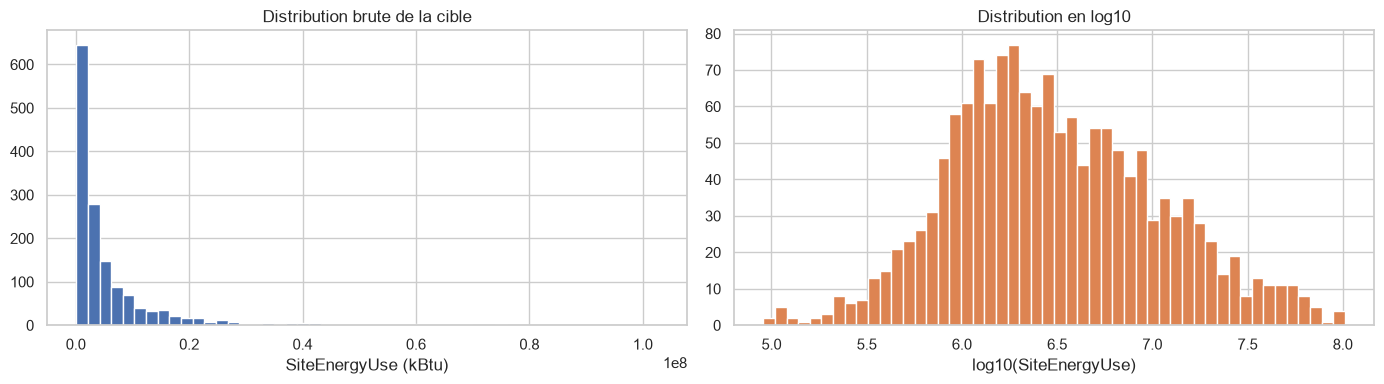

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df[TARGET], bins=50, color="#4c72b0", edgecolor="white")
axes[0].set_title("Distribution brute de la cible")
axes[0].set_xlabel("SiteEnergyUse (kBtu)")
axes[1].hist(np.log10(df[TARGET]), bins=50, color="#dd8452", edgecolor="white")
axes[1].set_title("Distribution en log10")
axes[1].set_xlabel("log10(SiteEnergyUse)")
plt.tight_layout(); plt.show()

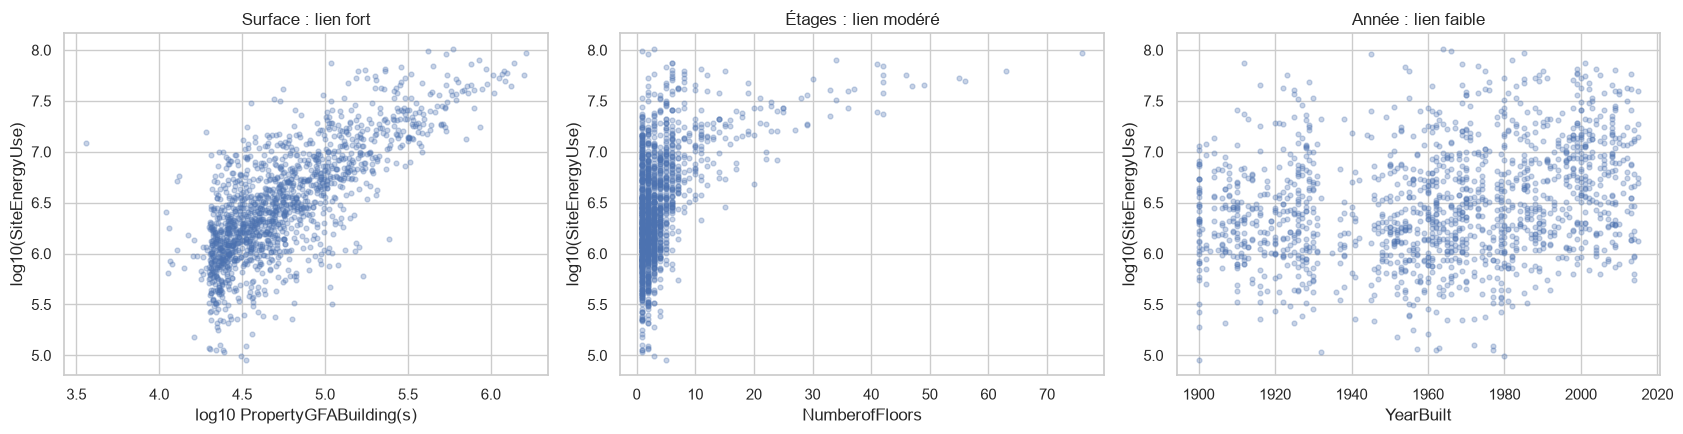

In [86]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["PropertyGFABuilding(s)", "NumberofFloors", "YearBuilt"]):
    x = np.log10(df[col]) if col == "PropertyGFABuilding(s)" else df[col]
    ax.scatter(x, np.log10(df[TARGET]), alpha=0.3, s=12)
    ax.set_xlabel(("log10 " if col == "PropertyGFABuilding(s)" else "") + col)
    ax.set_ylabel("log10(SiteEnergyUse)")
axes[0].set_title("Surface : lien fort")
axes[1].set_title("Étages : lien modéré")
axes[2].set_title("Année : lien faible")
plt.tight_layout(); plt.show()

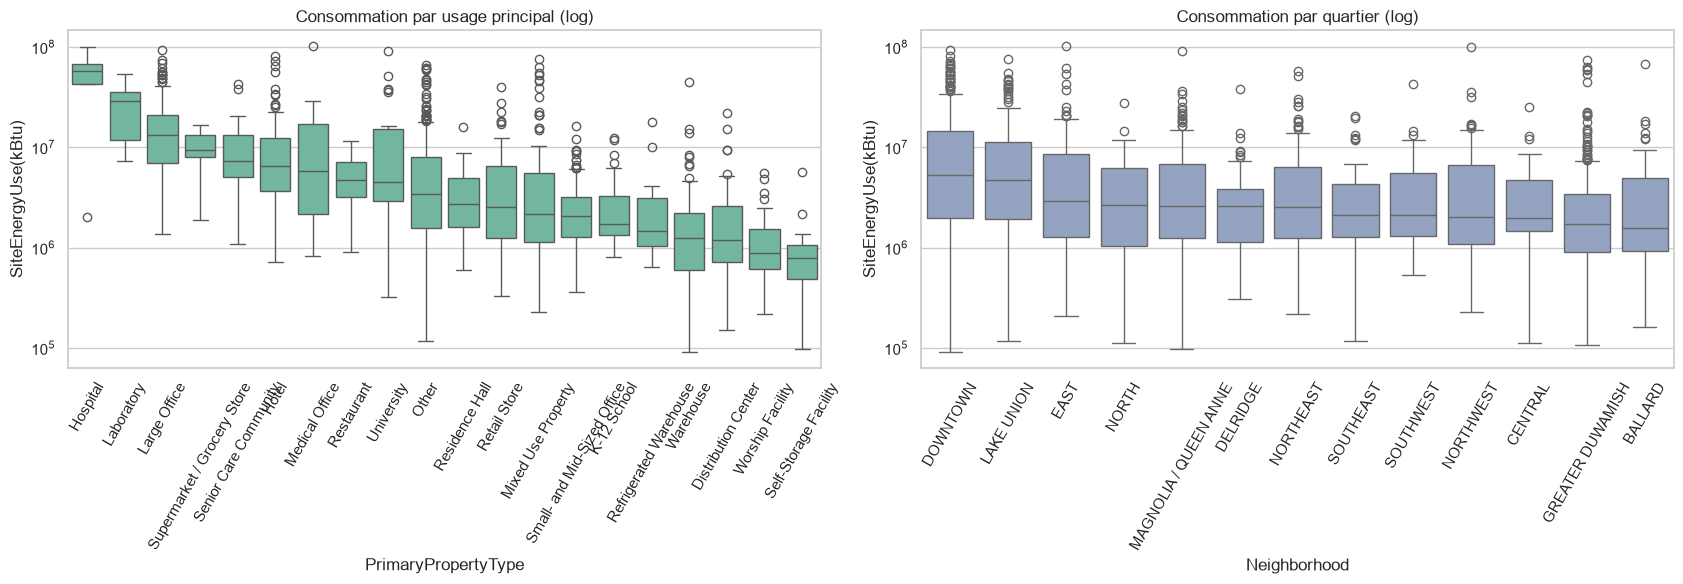

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

order = df.groupby("PrimaryPropertyType")[TARGET].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="PrimaryPropertyType", y=TARGET, order=order, color="#66c2a5", ax=axes[0])
axes[0].set_yscale("log"); axes[0].tick_params(axis="x", rotation=60)
axes[0].set_title("Consommation par usage principal (log)")

order_n = df.groupby("Neighborhood")[TARGET].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="Neighborhood", y=TARGET, order=order_n, color="#8da0cb", ax=axes[1])
axes[1].set_yscale("log"); axes[1].tick_params(axis="x", rotation=60)
axes[1].set_title("Consommation par quartier (log)")
plt.tight_layout(); plt.show()

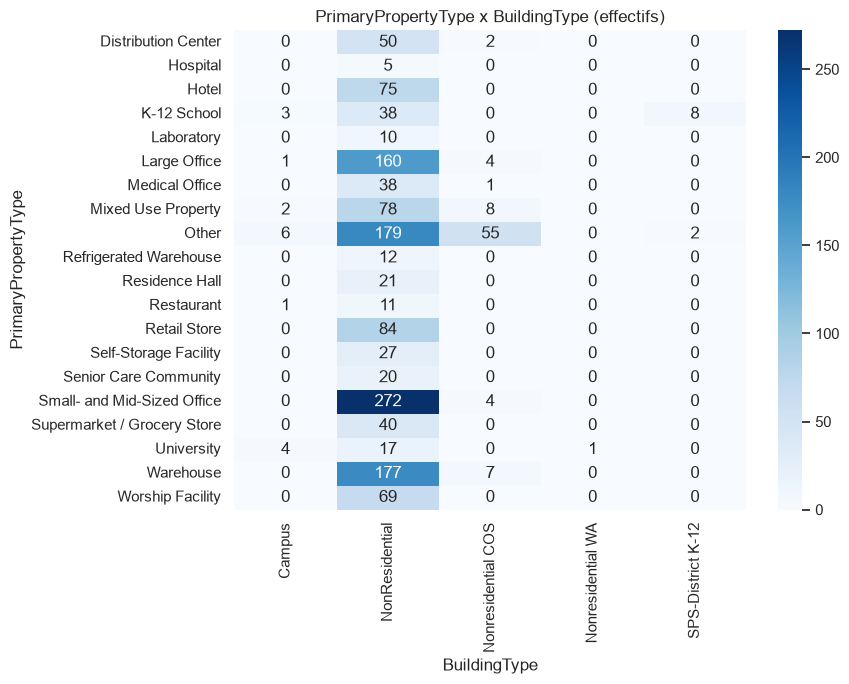

In [88]:
ct = pd.crosstab(df["PrimaryPropertyType"], df["BuildingType"])
plt.figure(figsize=(9, 7))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("PrimaryPropertyType x BuildingType (effectifs)")
plt.tight_layout(); plt.show()

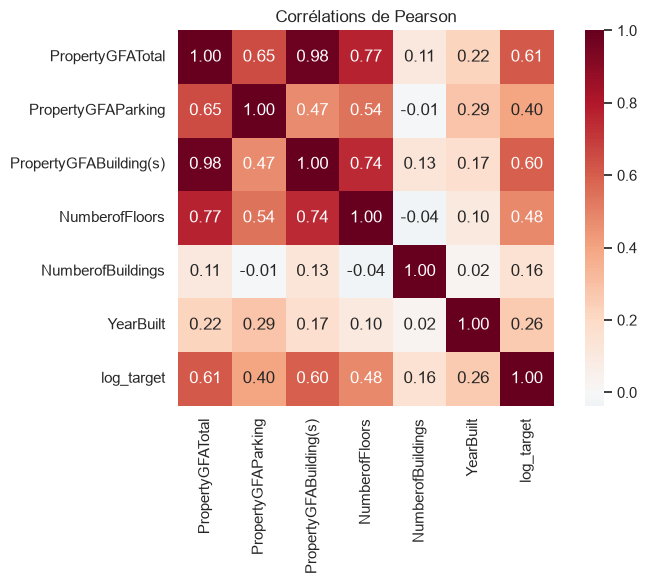

In [89]:
corr_df = df[["PropertyGFATotal", "PropertyGFAParking", "PropertyGFABuilding(s)",
              "NumberofFloors", "NumberofBuildings", "YearBuilt"]].copy()
corr_df["log_target"] = np.log10(df[TARGET])

plt.figure(figsize=(8, 6))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Corrélations de Pearson")
plt.tight_layout(); plt.show()

### Détection des outliers

Les outliers sont traités dans `clean_dataset` (voir `script/clean_rows.py`), avec **deux critères complémentaires** :

1. **Valeur absolue de la cible** (méthode de Tukey sur `log10(SiteEnergyUse)`) : retire les consommations extrêmes en valeur absolue.
2. **Intensité par type d'usage** (consommation / surface, comparée à la médiane de son `PrimaryPropertyType`) : retire les consommations **incohérentes avec la taille** du bâtiment, que Tukey ne voit pas (par exemple un petit bâtiment qui consomme comme un gros). L'intensité sert uniquement à **détecter** ces cas, jamais de variable d'entrée (elle est calculée avec la cible).

Les bâtiments retirés et les seuils sont affichés dans la sortie du nettoyage plus haut, et le nombre de lignes perdues figure dans le journal.


In [90]:
print(log.summary())
print("Colonnes restantes :", df.shape[1])
print("Valeurs manquantes restantes :")
display(df.isna().sum()[lambda s: s > 0].to_frame("nb manquants"))


Bilan : 3376 -> 1492 lignes (-1884, soit 55.8% de perte au total, 44.2% conservé)
Colonnes restantes : 38
Valeurs manquantes restantes :


,nb manquants
NumberofBuildings,50
NumberofFloors,15
YearsENERGYSTARCertified,1397
ENERGYSTARScore,519
SiteEUIWN(kBtu/sf),1
SiteEnergyUseWN(kBtu),1


### Conclusion de l'analyse exploratoire

- **Périmètre** : bâtiments non résidentiels, `Compliant`, sans outlier, soit **1 492 bâtiments** sur 3 376 au départ (44,2 % conservés). La moitié de la perte (50,6 points) vient de l'exclusion des immeubles d'habitation, un choix de périmètre imposé par l'énoncé ; les filtres de qualité retirent ensuite au plus 7,3 % par étape. Une dernière coupe sur les valeurs extrêmes des features, faite en préparation, ramène le jeu de modélisation à **1 472 bâtiments** (43,6 % du brut).
- **Règles qui conservent les lignes** : 50 nombres de bâtiments égaux à 0 et 16 nombres d'étages invalides passés en NaN (indicateurs `BuildingsMissing` et `FloorsMissing`), 4 plus grands usages imputés, 222 bâtiments aux surfaces d'usage incohérentes signalés (`GFAInconsistent`). Ces NaN sont imputés plus loin, dans le Pipeline, sur le train uniquement.
- **Outliers** : deux critères complémentaires, la valeur absolue de la cible (Tukey, 12 bâtiments) et l'intensité énergétique par type d'usage (6 bâtiments, par exemple un bureau de 85 000 sf à 446 kBtu/sf).
- **Cible** : `SiteEnergyUse(kBtu)`, très asymétrique, donc modélisée en **log**.
- La **surface** est le lien le plus net avec la cible (corrélation de Spearman ≈ 0,74 pour la surface totale et ≈ 0,72 pour `LogGFABuilding`). Le **type d'usage** discrimine fortement. L'âge, les étages et la localisation ont des effets plus modestes et souvent liés à la taille ou à l'usage : on les vérifiera avec l'importance des features.
- Les colonnes de consommation (EUI, gaz, électricité, GHG, ENERGYSTARScore) sont écartées comme features (**fuite de données**).
- Les NaN restants (65 valeurs sur deux colonnes, soit environ 4 % des bâtiments) seront imputés lors de la modélisation, sur le jeu d'entraînement uniquement.


# Feature Engineering

**Objectif** : enrichir le jeu de données avec de nouvelles variables calculées à partir des colonnes existantes, pour aider le modèle à mieux capter le lien entre un bâtiment et sa consommation.

**Règle d'or** : on ne crée que des variables que l'on peut calculer **sans aucun relevé de consommation** (pas de EUI, gaz, électricité, GHG, ENERGYSTARScore). Sinon, il y aurait fuite de données (*data leakage*) : en production, ces valeurs ne seraient pas connues.

| Famille | Idée |
|---|---|
| Âge | `BuildingAge`, `AgeClass` |
| Usage | `NumUseTypes`, `SecondUseShare`, `LargestUseShare`, `LargestUseFamily` |
| Surface | `ParkingShare`, `HasParking`, `GFAPerBuilding`, `GFAPerFloor`, `IsHighRise` |
| Transformation log | `LogGFABuilding`, `LogGFAParking` |
| Localisation | `DistDowntownKm` |

In [91]:
data = df.copy()
print("Shape avant feature engineering :", data.shape)

Shape avant feature engineering : (1492, 38)


In [92]:
# BuildingAge (année de référence 2016) et tranches d'âge : script/features.py
data = add_age_features(data)

data[["YearBuilt", "BuildingAge", "AgeClass"]].head()


,YearBuilt,BuildingAge,AgeClass
0,1927,89,>80 ans
1,1996,20,<=20 ans
2,1969,47,21-50 ans
3,1926,90,>80 ans
4,1980,36,21-50 ans


**Pourquoi ?** `YearBuilt` est une année brute, peu parlante pour un modèle. L'âge est plus intuitif. Son effet sur la consommation n'est toutefois pas évident (voir les tendances) : un bâtiment ancien n'est pas forcément plus énergivore. Les tranches d'âge servent à observer cet effet.

In [93]:
# NumUseTypes, parts de surface (LargestUseShare, SecondUseShare) et famille d'usage : script/features.py
data = add_use_features(data)

display(data[["ListOfAllPropertyUseTypes", "NumUseTypes", "LargestUseShare", "SecondUseShare",
              "LargestPropertyUseType", "LargestUseFamily"]].head())
display(data["LargestUseFamily"].value_counts().to_frame("nb bâtiments"))


,ListOfAllPropertyUseTypes,NumUseTypes,LargestUseShare,SecondUseShare,LargestPropertyUseType,LargestUseFamily
0,Hotel,1,1.000000,0.000000,Hotel,Lodging / Care
1,"Hotel, Parking, Restaurant",3,0.809918,0.145453,Hotel,Lodging / Care
2,Hotel,1,0.791220,0.000000,Hotel,Lodging / Care
3,Hotel,1,1.000000,0.000000,Hotel,Lodging / Care
4,"Hotel, Parking, Swimming Pool",3,0.644776,0.355224,Hotel,Lodging / Care


,nb bâtiments
LargestUseFamily,
Office,473
Warehouse / Storage,287
Retail / Food,161
Assembly / Leisure,148
Lodging / Care,122
Other,96
Education,78
Health,54
Parking,28


**Pourquoi ?**
- `NumUseTypes` compte les usages distincts ; les parts de surface décrivent la répartition entre usage principal et usage secondaire.
- Les surfaces d'usage déclarées dépassent parfois la surface totale (règle `GFAInconsistent` du nettoyage). Les parts sont donc calculées sur le **maximum entre la surface totale et la somme des surfaces d'usage** : elles restent entre 0 et 1 sans écrêtage artificiel.
- `LargestUseFamily` regroupe les 52 types d'usage détaillés en une douzaine de **familles métier** (bureaux, entrepôts, commerce…) selon des règles fixes (`USE_FAMILY_RULES` dans `script/config.py`). Le regroupement ne dépend pas des données, donc aucune fuite entre train et test.

In [94]:
# ParkingShare, HasParking, GFAPerBuilding, GFAPerFloor, IsHighRise, surfaces en log : script/features.py
data = add_surface_features(data)

data[["ParkingShare", "HasParking", "GFAPerBuilding", "GFAPerFloor", "IsHighRise", "LogGFABuilding"]].head()


,ParkingShare,HasParking,GFAPerBuilding,GFAPerFloor,IsHighRise,LogGFABuilding
0,0.000000,0,88434.0,7369.500000,1.0,11.390023
1,0.145453,1,88502.0,8045.636364,1.0,11.390792
2,0.205748,1,759392.0,18521.756098,1.0,13.540275
3,0.000000,0,61320.0,6132.000000,1.0,11.023878
4,0.353115,1,113580.0,6310.000000,1.0,11.640272


**Pourquoi ?**
- Les surfaces sont très asymétriques (quelques très grands sites), d'où le log.
- Les ratios (`ParkingShare`, `GFAPerFloor`...) décrivent la *forme* du bâtiment indépendamment de sa taille.
- `HasParking` et `IsHighRise` sont des indicateurs simples (0/1) qui capturent des effets de seuil.

In [95]:
# Distance approximative au centre-ville de Seattle (km) : script/features.py
data = add_location_features(data)

data["DistDowntownKm"].describe().round(2).to_frame().T


,count,mean,std,min,25%,50%,75%,max
DistDowntownKm,1492.0,4.43,3.54,0.03,1.37,3.42,6.66,14.24


**Pourquoi ?** Latitude et longitude seules sont peu exploitables par un modèle. La distance au centre-ville résume la localisation en un seul chiffre, avec une idée métier : le centre est plus dense et concentre les grands immeubles de bureaux.


In [96]:
new_features = NEW_FEATURES   # définies dans script/features.py

display(data[new_features].describe().round(2).T)

print("Valeurs manquantes dans les nouvelles variables :")
display(data[new_features].isna().sum()[lambda s: s > 0].to_frame("nb manquants"))
print("Valeurs infinies :", np.isinf(data[new_features]).sum().sum())
print("Shape après feature engineering :", data.shape)


,count,mean,std,min,25%,50%,75%,max
BuildingAge,1492.0,54.29,32.49,1.00,28.00,51.00,86.00,116.00
NumUseTypes,1492.0,1.90,1.19,1.00,1.00,2.00,2.00,13.00
LargestUseShare,1492.0,0.82,0.20,0.19,0.66,0.91,1.00,1.00
SecondUseShare,1492.0,0.12,0.15,0.00,0.00,0.00,0.23,0.50
ParkingShare,1492.0,0.07,0.14,0.00,0.00,0.00,0.00,0.90
HasParking,1492.0,0.21,0.41,0.00,0.00,0.00,0.00,1.00
GFAPerBuilding,1442.0,91885.84,150771.94,3636.00,27169.75,43907.50,89316.25,1632820.00
GFAPerFloor,1477.0,30163.63,39280.07,1818.00,12110.50,20511.00,31944.00,530039.00
IsHighRise,1477.0,0.08,0.27,0.00,0.00,0.00,0.00,1.00
LogGFABuilding,1492.0,10.94,0.89,8.20,10.23,10.73,11.45,14.31


Valeurs manquantes dans les nouvelles variables :


,nb manquants
GFAPerBuilding,50
GFAPerFloor,15
IsHighRise,15


Valeurs infinies : 0
Shape après feature engineering : (1492, 52)


In [97]:
# Contrôle : le pas-à-pas ci-dessus équivaut à build_features (script/features.py)
assert build_features(df).drop(columns="LogTarget").equals(data), "pas-à-pas et build_features divergent"
print("Contrôle OK : pas-à-pas == build_features")

Contrôle OK : pas-à-pas == build_features


,Spearman avec log10(conso)
BuildingAge,-0.28
DistDowntownKm,-0.26
LargestUseShare,-0.19
SecondUseShare,0.16
NumUseTypes,0.22
GFAPerFloor,0.25
ParkingShare,0.33
LogGFAParking,0.37
GFAPerBuilding,0.68
LogGFABuilding,0.72


Spearman, surface totale vs log10(conso) : 0.74


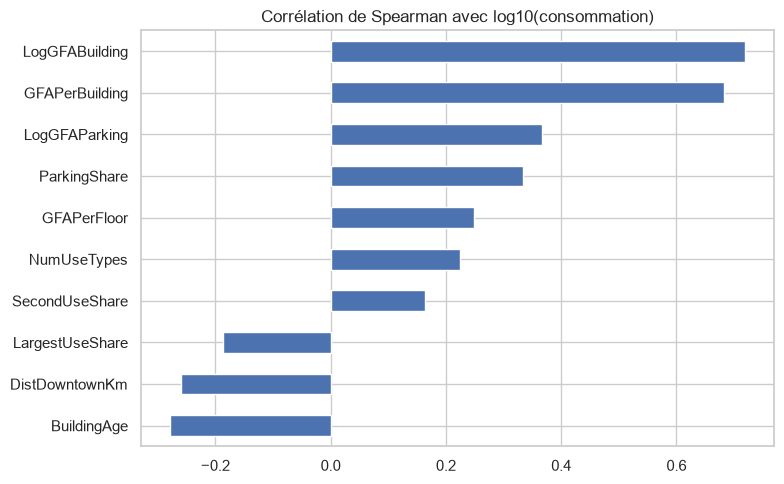

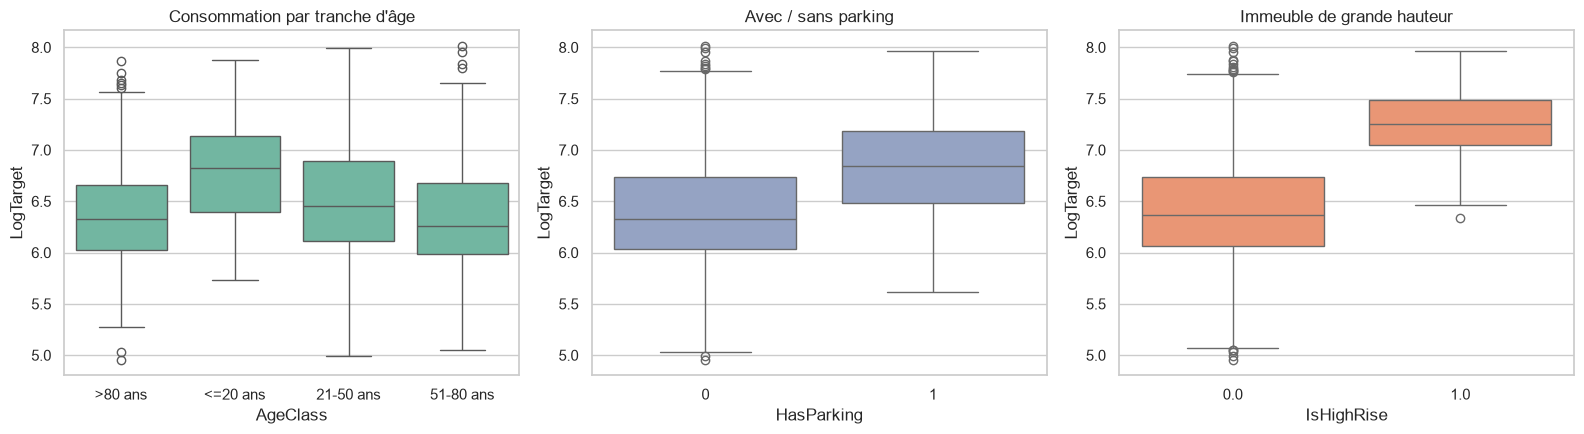

In [98]:
data["LogTarget"] = np.log10(data[TARGET])

# Quanti vs quanti : corrélation de Spearman avec la cible
num_new = ["LogGFABuilding", "LogGFAParking", "GFAPerBuilding", "GFAPerFloor", "BuildingAge",
           "NumUseTypes", "LargestUseShare", "SecondUseShare", "ParkingShare", "DistDowntownKm"]
corr_target = data[num_new + ["LogTarget"]].corr(method="spearman")["LogTarget"].drop("LogTarget")
display(corr_target.sort_values().round(2).to_frame("Spearman avec log10(conso)"))
print("Spearman, surface totale vs log10(conso) :", round(data[["PropertyGFATotal", "LogTarget"]].corr(method="spearman").iloc[0, 1], 2))
corr_target.sort_values().plot.barh(figsize=(8, 5), color="#4c72b0")
plt.title("Corrélation de Spearman avec log10(consommation)")
plt.tight_layout(); plt.show()

# Quanti vs quali : effet des variables binaires et de la tranche d'âge
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=data, x="AgeClass", y="LogTarget", ax=axes[0], color="#66c2a5")
axes[0].set_title("Consommation par tranche d'âge")
sns.boxplot(data=data, x="HasParking", y="LogTarget", ax=axes[1], color="#8da0cb")
axes[1].set_title("Avec / sans parking")
sns.boxplot(data=data, x="IsHighRise", y="LogTarget", ax=axes[2], color="#fc8d62")
axes[2].set_title("Immeuble de grande hauteur")
plt.tight_layout(); plt.show()

### Bilan du feature engineering

- **14 nouvelles variables** créées (12 numériques ou binaires, plus la tranche d'âge `AgeClass` et la famille d'usage `LargestUseFamily`), toutes calculables sans relevé de consommation (aucune fuite de données). Le code vit dans `script/features.py`.
- `LogGFABuilding` est la plus liée à la cible (Spearman ≈ 0,72), puis `GFAPerBuilding` (≈ 0,68) : la **surface** domine.
- `HasParking` et `IsHighRise` séparent des groupes de consommation différents ; `ParkingShare` a un lien modéré (≈ 0,33).
- `BuildingAge` et `DistDowntownKm` ont un lien faible avec la cible (corrélations de Spearman d'environ −0,28 et −0,26), nettement inférieur à celui de la surface.
- Plusieurs variables sont redondantes entre elles (`PropertyGFATotal`, `PropertyGFABuilding(s)`, `GFAPerBuilding`…) : on les triera avec la matrice de corrélation.

# Préparation des features pour la modélisation

Étapes :
1. Retirer les colonnes inutiles ou **leaky** (liées à la consommation).
2. Traiter les valeurs extrêmes des features, avec des seuils sur quantiles.
3. Examiner la cible et dégager des tendances.
4. Éliminer les features redondantes (matrice de corrélation, **variables numériques uniquement**).
5. Séparer X et y, puis encoder les variables qualitatives.

In [99]:
# Colonnes de consommation (fuite de données) : liste LEAKAGE_COLS de script/config.py.
# TotalGHGEmissions est conservée pour l'extension double cible.
data = drop_leakage_columns(data, keep=SECOND_TARGET)

NOT_RELEVANT = [
    "OSEBuildingID", "CouncilDistrictCode",          # identifiants
    "Latitude", "Longitude",                          # résumés par DistDowntownKm
    "YearBuilt",                                      # résumé par BuildingAge
    "ListOfAllPropertyUseTypes",                      # résumé par NumUseTypes
    "LargestPropertyUseType",                         # résumé par LargestUseFamily (52 modalités -> regroupées)
    "SecondLargestPropertyUseType", "ThirdLargestPropertyUseType",
    "SecondLargestPropertyUseTypeGFA", "ThirdLargestPropertyUseTypeGFA",
]

data = data.drop(columns=[c for c in NOT_RELEVANT if c in data.columns])
print("Shape :", data.shape)
print("Colonnes restantes :", data.columns.tolist())


Shape : (1492, 29)
Colonnes restantes : ['BuildingType', 'PrimaryPropertyType', 'Neighborhood', 'NumberofBuildings', 'NumberofFloors', 'PropertyGFATotal', 'PropertyGFAParking', 'PropertyGFABuilding(s)', 'LargestPropertyUseTypeGFA', 'SiteEnergyUse(kBtu)', 'TotalGHGEmissions', 'BuildingsMissing', 'FloorsMissing', 'GFAInconsistent', 'BuildingAge', 'AgeClass', 'NumUseTypes', 'LargestUseShare', 'SecondUseShare', 'LargestUseFamily', 'ParkingShare', 'HasParking', 'GFAPerBuilding', 'GFAPerFloor', 'IsHighRise', 'LogGFABuilding', 'LogGFAParking', 'DistDowntownKm', 'LogTarget']


**Arguments** : les colonnes de consommation (EUI, gaz, électricité, vapeur, GHG) sont calculées **à partir** de la consommation. Les donner au modèle reviendrait à lui donner la réponse. `ENERGYSTARScore` et la certification dépendent aussi de la performance mesurée. Les identifiants n'ont pas de valeur prédictive, et les colonnes brutes ont déjà été résumées (`LargestPropertyUseType` par `LargestUseFamily`, la latitude et la longitude par `DistDowntownKm`, etc.). Les indicateurs `FloorsMissing`, `BuildingsMissing` et `GFAInconsistent`, créés au nettoyage, restent dans les fichiers clean/model pour la traçabilité mais ne sont pas testés comme features : l'imputation des étages est faite dans le Pipeline et les incohérences de surface sont déjà neutralisées par les parts d'usage. La liste des colonnes de fuite est centralisée dans `LEAKAGE_COLS` (`script/config.py`).

In [100]:
data = drop_feature_extremes(data, log)   # script/preprocessing.py : seuils affichés + journal

# Journal complet : nettoyage + préparation, avec les % de perte
display(log.to_frame())
print(log.summary())

NumberofBuildings : seuil 99,5 % = 7.6 -> 8 bâtiments au-dessus
GFAPerFloor : seuil 99,5 % = 265,361.6 -> 8 bâtiments au-dessus
NumUseTypes : seuil 99,5 % = 6.0 -> 7 bâtiments au-dessus
Suppression des valeurs extrêmes de features (quantile 99,5 %) : 1492 -> 1472 (-20 lignes, -1.3% vs précédent, 43.6% du brut restant)


,étape,avant,après,supprimées,% perdu vs étape précédente,% perdu vs brut,% restant vs brut
0,Exclusion Multifamily (BuildingType),3376,1668,1708,50.59,50.59,49.41
1,Exclusion Multifamily (colonnes d'usage),1668,1629,39,2.34,1.16,48.25
2,Conservation des seuls Compliant,1629,1510,119,7.31,3.52,44.73
3,Suppression cible manquante ou <= 0,1510,1510,0,0.00,0.00,44.73
4,Suppression des outliers (Tukey sur log10 de l...,1510,1498,12,0.79,0.36,44.37
5,Suppression des outliers d'intensité (par type...,1498,1492,6,0.40,0.18,44.19
6,Suppression des valeurs extrêmes de features (...,1492,1472,20,1.34,0.59,43.60


Bilan : 3376 -> 1472 lignes (-1904, soit 56.4% de perte au total, 43.6% conservé)


**Argument** : un IQR ou un z-score supprimerait trop de bâtiments, car ces variables sont très asymétriques. On coupe donc seulement le **0,5 % supérieur** : on retire les cas vraiment atypiques (campus de 27 bâtiments, 13 usages…) sans réduire le jeu de données.

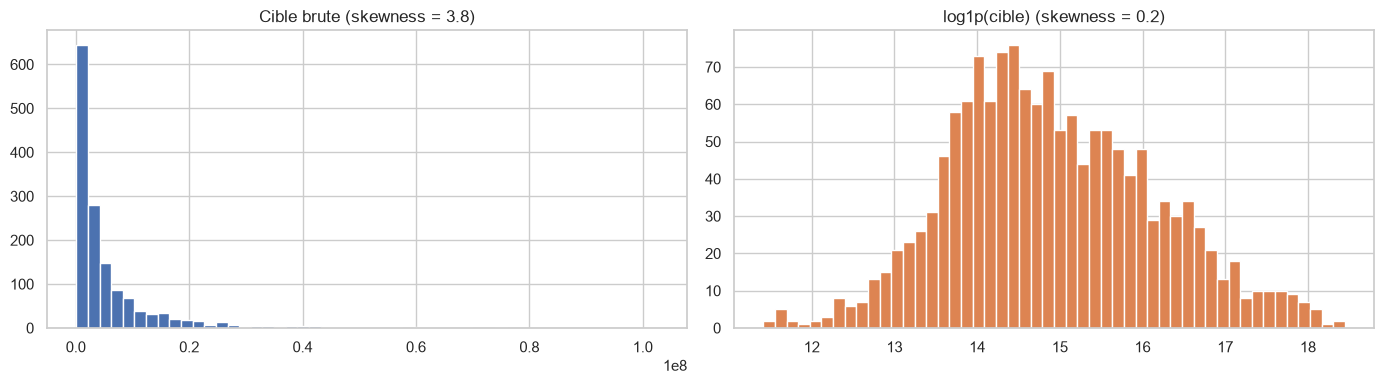

In [101]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(data[TARGET], bins=50, color="#4c72b0", edgecolor="white")
axes[0].set_title(f"Cible brute (skewness = {data[TARGET].skew():.1f})")
axes[1].hist(np.log1p(data[TARGET]), bins=50, color="#dd8452", edgecolor="white")
axes[1].set_title(f"log1p(cible) (skewness = {np.log1p(data[TARGET]).skew():.1f})")
plt.tight_layout(); plt.show()

,count,median
PrimaryPropertyType,,
Hospital,4,50237016.0
Laboratory,10,28831819.0
Large Office,163,12729858.0
Supermarket / Grocery Store,40,9313226.0
Senior Care Community,20,7366733.0
Hotel,75,6505995.0
Medical Office,39,5792926.0
Restaurant,12,4722848.0
University,19,3543986.0


,médiane
AgeClass,
21-50 ans,2776944.0
51-80 ans,1806468.0
<=20 ans,6504464.0
>80 ans,2100983.0


,médiane
HasParking,
0,2070006.0
1,6876440.0


,surface_mediane,part_grands_bureaux
AgeClass,,
21-50 ans,45041.0,0.14
51-80 ans,35400.0,0.03
<=20 ans,82437.0,0.22
>80 ans,40800.0,0.07


,surface médiane
HasParking,
0,39600.0
1,87576.0


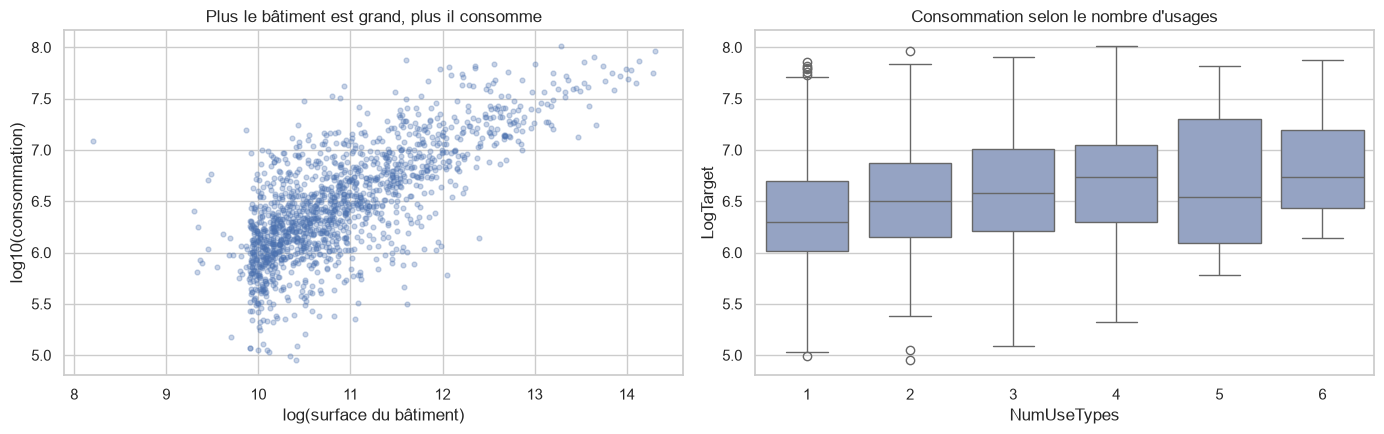

In [102]:
data["LogTarget"] = np.log10(data[TARGET])

# Par usage principal : médiane de la consommation
display(
    data.groupby("PrimaryPropertyType")[TARGET].agg(["count", "median"])
    .sort_values("median", ascending=False).round(0)
)

# Par tranche d'âge et par présence de parking
display(data.groupby("AgeClass", observed=True)[TARGET].median().round(0).to_frame("médiane"))
display(data.groupby("HasParking")[TARGET].median().round(0).to_frame("médiane"))

# Effets de confusion : l'âge et le parking sont liés à la taille et à l'usage
conf = data.groupby("AgeClass", observed=True).agg(
    surface_mediane=("PropertyGFABuilding(s)", "median"),
    part_grands_bureaux=("PrimaryPropertyType", lambda s: (s == "Large Office").mean()),
)
display(conf.round(2))
display(data.groupby("HasParking")["PropertyGFABuilding(s)"].median().round(0).to_frame("surface médiane"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(data["LogGFABuilding"], data["LogTarget"], alpha=0.3, s=12)
axes[0].set_xlabel("log(surface du bâtiment)"); axes[0].set_ylabel("log10(consommation)")
axes[0].set_title("Plus le bâtiment est grand, plus il consomme")
sns.boxplot(data=data, x="NumUseTypes", y="LogTarget", ax=axes[1], color="#8da0cb")
axes[1].set_title("Consommation selon le nombre d'usages")
plt.tight_layout(); plt.show()

**Tendances observées** :
- **Surface** : c'est le lien le plus net (corrélation de Spearman ≈ 0,74 avec le log de la consommation).
- **Usage** : les médianes les plus élevées sont celles des hôpitaux (≈ 50,2 M kBtu, mais seulement **4 bâtiments** après suppression des outliers), des laboratoires (≈ 28,8 M), des grands bureaux (≈ 12,7 M) et des supermarchés (≈ 9,3 M). Les plus basses sont celles des lieux de culte (≈ 0,9 M), des self-storage (≈ 0,8 M), des centres de distribution et des entrepôts (≈ 1,2 M). Les universités (19 bâtiments) sont en position intermédiaire (≈ 3,5 M).
- **Âge** : l'effet n'est **pas monotone**. Les bâtiments de 20 ans ou moins consomment le plus (médiane ≈ 6,5 M kBtu), contre ≈ 1,8 M pour les 51-80 ans. Ils sont aussi plus grands (surface médiane ≈ 82 k contre 35 à 45 k pour les autres tranches) et comptent plus de grands bureaux (22 % contre 3 à 14 %) : l'effet de l'âge est en grande partie lié à la taille et à l'usage.
- **Parking** : les bâtiments avec parking consomment davantage (médiane ≈ 6,9 M contre ≈ 2,1 M), mais ils sont aussi nettement plus grands (surface médiane ≈ 88 k contre ≈ 40 k).
- **Localisation** : la distance au centre-ville est faiblement et négativement liée à la consommation (Spearman ≈ −0,27).

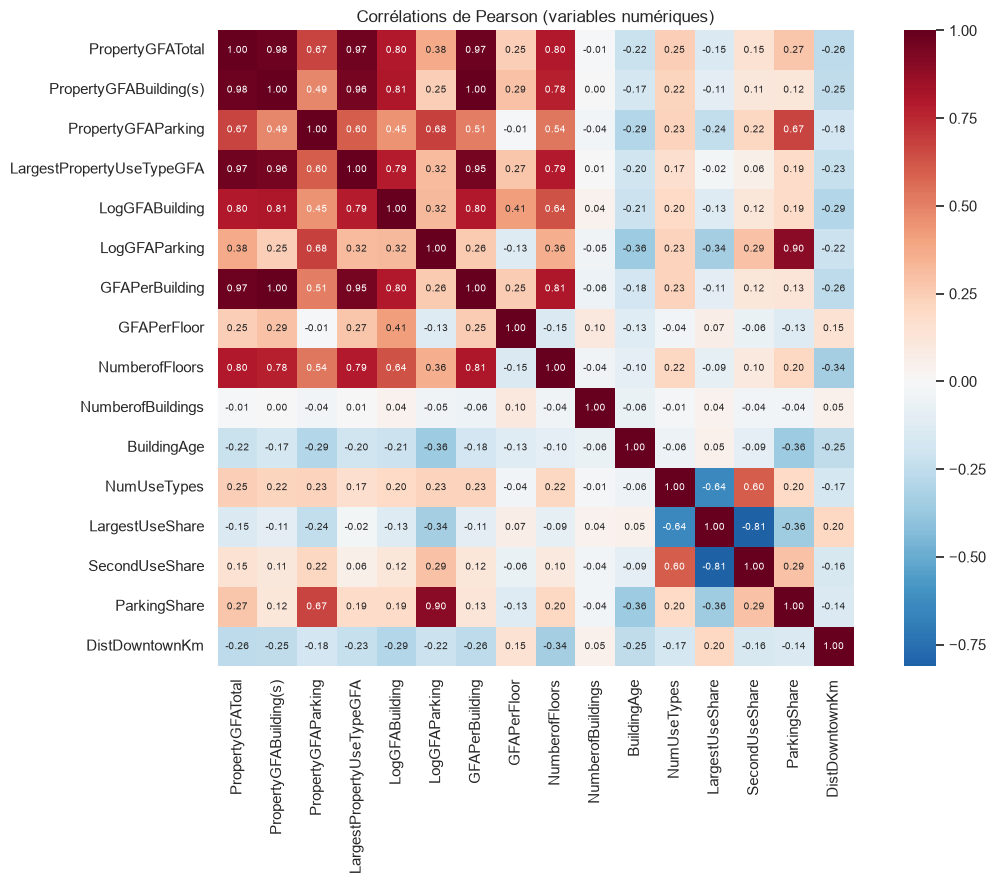

,var 1,var 2,corrélation
0,PropertyGFATotal,PropertyGFABuilding(s),0.98
1,PropertyGFATotal,LargestPropertyUseTypeGFA,0.97
2,PropertyGFATotal,GFAPerBuilding,0.97
3,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,0.96
4,PropertyGFABuilding(s),LogGFABuilding,0.81
5,PropertyGFABuilding(s),GFAPerBuilding,1.00
6,LargestPropertyUseTypeGFA,GFAPerBuilding,0.95
7,LogGFABuilding,GFAPerBuilding,0.80
8,LogGFAParking,ParkingShare,0.90
9,GFAPerBuilding,NumberofFloors,0.81


In [103]:
num_candidates = [
    "PropertyGFATotal", "PropertyGFABuilding(s)", "PropertyGFAParking", "LargestPropertyUseTypeGFA",
    "LogGFABuilding", "LogGFAParking", "GFAPerBuilding", "GFAPerFloor",
    "NumberofFloors", "NumberofBuildings", "BuildingAge", "NumUseTypes",
    "LargestUseShare", "SecondUseShare", "ParkingShare", "DistDowntownKm",
]
corr = data[num_candidates].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, annot_kws={"size": 7})
plt.title("Corrélations de Pearson (variables numériques)")
plt.tight_layout(); plt.show()

# Paires fortement corrélées (|r| > 0,8)
paires = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(num_candidates)
          for b in num_candidates[i + 1:] if abs(corr.loc[a, b]) > 0.8]
display(pd.DataFrame(paires, columns=["var 1", "var 2", "corrélation"]))

**Lecture** : les surfaces brutes (`PropertyGFATotal`, `PropertyGFABuilding(s)`, `LargestPropertyUseTypeGFA`) sont quasi identiques (r ≥ 0,95) et corrélées à `GFAPerBuilding`. On ne garde que **`LogGFABuilding`**, plus symétrique. `LogGFAParking` et `ParkingShare` sont aussi très liées (r ≈ 0,9) : on garde `ParkingShare` + `HasParking`. `LargestUseShare` et `SecondUseShare` sont liées entre elles (r ≈ −0,81) : on les garde toutes les deux, car elles portent des informations différentes (usage dominant contre usage secondaire) et les modèles à arbres tolèrent bien cette redondance.

⚠️ La corrélation de Pearson ne s'applique **qu'aux variables numériques**. Pour les variables qualitatives (usage, quartier…), on utilise des boxplots ou des tableaux croisés.

In [104]:
def controle_qualite(frame, name="jeu"):
    """Échoue si une anomalie corrigée plus haut réapparaît."""
    assert (frame["NumberofBuildings"].dropna() > 0).all(), "NumberofBuildings <= 0 présent"
    assert not np.isinf(frame.select_dtypes("number")).any().any(), "Valeur infinie présente"
    assert (frame["NumberofFloors"].dropna() > 0).all(), "NumberofFloors = 0 présent"
    assert (frame["NumberofFloors"].dropna() <= MAX_FLOORS).all(), "Étages aberrants présents"
    print(f"{name} : contrôle OK ({len(frame)} lignes, "
          f"{frame['NumberofFloors'].isna().sum()} étages et {frame['NumberofBuildings'].isna().sum()} nombres de bâtiments à imputer dans le Pipeline)")

controle_qualite(data, "data")

data : contrôle OK (1472 lignes, 13 étages et 50 nombres de bâtiments à imputer dans le Pipeline)


In [105]:
numeric_features, categorical_features = NUMERIC_FEATURES, CATEGORICAL_FEATURES   # script/modeling.py

X = data[numeric_features + categorical_features]
y = data[TARGET]
print("X :", X.shape, "| y :", y.shape)

print("\nValeurs manquantes à imputer :")
display(X.isna().sum()[lambda s: s > 0].to_frame("nb manquants"))
print("\nNombre de modalités par variable qualitative :")
display(X[categorical_features].nunique().to_frame("modalités"))

X : (1472, 16) | y : (1472,)

Valeurs manquantes à imputer :


,nb manquants
NumberofFloors,13
NumberofBuildings,50
GFAPerFloor,13
IsHighRise,13



Nombre de modalités par variable qualitative :


,modalités
BuildingType,5
PrimaryPropertyType,20
Neighborhood,13
LargestUseFamily,12


### OneHotEncoder ou LabelEncoder ?

- **LabelEncoder** (0, 1, 2…) crée un **ordre artificiel** : le modèle croirait que `DOWNTOWN` (3) > `BALLARD` (1). Il convient aux **variables ordinales** (ex. petit < moyen < grand) ou à la cible.
- **OneHotEncoder** crée une colonne 0/1 par modalité, sans ordre. Il convient aux **variables nominales** (usage, quartier, type de bâtiment).
- Pour une variable à **beaucoup de modalités**, on limite le nombre de colonnes de deux façons. `LargestPropertyUseType` (54 modalités) a d'abord été regroupée en 12 **familles métier** (`LargestUseFamily`). Ensuite, `max_categories` (15, constante `OHE_MAX_CATEGORIES`) regroupe les modalités rares dans « infrequent », ce qui évite des dizaines de colonnes quasi vides.

In [106]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = split_xy(data, test_size=0.2, random_state=RANDOM_STATE)
print("Train :", X_train.shape[0], "| Test :", X_test.shape[0])

preprocessor = make_preprocessor(X_train)

X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)
print("Train encodé :", X_train_enc.shape, "| Test encodé :", X_test_enc.shape)
print("NaN restants :", np.isnan(X_train_enc).sum())

Train : 1177 | Test : 295
Numériques (12) : ['LogGFABuilding', 'NumberofFloors', 'NumberofBuildings', 'GFAPerFloor', 'BuildingAge', 'NumUseTypes', 'LargestUseShare', 'SecondUseShare', 'ParkingShare', 'DistDowntownKm', 'HasParking', 'IsHighRise']
Catégorielles (4) : ['BuildingType', 'PrimaryPropertyType', 'Neighborhood', 'LargestUseFamily']
Train encodé : (1177, 57) | Test encodé : (295, 57)
NaN restants : 0


### Questions qu'on pourrait me poser

| Question | Réponse |
|---|---|
| Pourquoi retirer `ENERGYSTARScore`, `Electricity`, `NaturalGas` ? | Ces valeurs sont calculées à partir de la consommation ou la reflètent : le modèle « tricherait ». En production, on ne les a pas. |
| Pourquoi ne pas supprimer toutes les lignes avec NaN ? | On perdrait trop de bâtiments. On impute (médiane ou modalité la plus fréquente), sur le train seulement. |
| Pourquoi un seuil à 99,5 % pour les extrêmes ? | IQR et z-score retirent trop de bâtiments sur des variables asymétriques. Les quantiles gardent presque tout le jeu de données (20 bâtiments retirés, 1,3 %). |
| Pourquoi deux critères d'outliers (Tukey et intensité) ? | Tukey ne voit que les consommations extrêmes en valeur absolue. L'intensité par type d'usage détecte les consommations incohérentes avec la taille du bâtiment. Elle sert à détecter, jamais de variable d'entrée. |
| Pourquoi perdre 56,4 % du jeu brut ? | 50,6 points viennent de l'exclusion des immeubles d'habitation, imposée par l'énoncé. Le nettoyage de qualité en retire environ 6 points de plus (3,5 points de non-conformes, 0,4 d'outliers de la cible, 0,2 d'outliers d'intensité, 0,6 de valeurs extrêmes de features, plus 1,2 d'usages multifamily détectés dans les colonnes d'usage). |
| Pourquoi OneHot et pas LabelEncoder ? | Quartier et usage sont nominaux : un numéro imposerait un ordre qui n'existe pas. |
| Pourquoi regrouper les usages en familles ? | 54 modalités dont 33 de moins de 10 bâtiments : trop de colonnes quasi vides. Le regroupement est fixé par des règles métier, pas par les données, donc sans fuite entre train et test. |
| Pourquoi `max_categories` ? | Il limite le nombre de colonnes à 15 par variable, en regroupant les modalités rares. |
| Pourquoi imputer après le split ? | Pour que la médiane vienne du train. Sinon des infos du test fuiraient vers l'entraînement. |
| Pourquoi la matrice de corrélation seulement sur le numérique ? | Pearson mesure un lien linéaire entre deux nombres. Elle n'a pas de sens sur des catégories. |
| Les seuils de nettoyage sont-ils calculés avant le split ? | Oui (Tukey, intensité, quantile 99,5 %), sur tout le jeu. L'effet est marginal (quelques dizaines de lignes), mais une version stricte les recalculerait sur le train seul. |

# Comparaison de différents modèles supervisés

**Démarche (identique pour tous les modèles)** :
- Mêmes données : `X_train` / `y_train` (même nombre de lignes, même séparation).
- Même validation : **validation croisée à 5 plis**, avec `random_state` fixé.
- Mêmes métriques : **R²**, **MAE** et **RMSE**, calculées sur le train et sur la validation.
- Même prétraitement, intégré dans un `Pipeline` : l'imputation et le scaling sont réappris à chaque pli, donc aucune fuite de données.
- Paramètres par défaut pour chaque algorithme (l'optimisation viendra en mission 5).

**Cible en log** : la consommation est très asymétrique. Le modèle apprend `log1p(consommation)` puis ses prédictions sont reconverties en kBtu (`TransformedTargetRegressor`). Les métriques restent exprimées en kBtu.

**Surapprentissage (*overfit*)** : un modèle qui a un excellent R² sur le train mais un R² bien plus faible en validation a « appris par cœur ».


In [107]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

In [108]:
# 1. Définition des paramètres de validation croisée et des métriques
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
}

# 2. FloorsImputer et make_model viennent de script/modeling.py (une seule définition)

def evaluate_model(name, estimator, X=X_train, y=y_train):
    """Validation croisée complète d'un modèle ; renvoie une ligne de résultats."""
    res = cross_validate(
        make_model(estimator), X, y,
        cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1,
    )
    return {
        "Modèle": name,
        "R² train": res["train_r2"].mean(),
        "R² validation": res["test_r2"].mean(),
        "Écart R² (train - val.)": res["train_r2"].mean() - res["test_r2"].mean(),
        "MAE validation": -res["test_mae"].mean(),
        "RMSE validation": -res["test_rmse"].mean(),
        "Écart-type R² val.": res["test_r2"].std(),
        "Temps d'entraînement (s)": res["fit_time"].mean(),
    }

print("Mêmes données pour tous les modèles :", X_train.shape, y_train.shape)

Mêmes données pour tous les modèles : (1177, 16) (1177,)


In [109]:
lin_result = evaluate_model("Régression linéaire", LinearRegression())
display_df = pd.Series(lin_result).apply(
    lambda x: round(x, 3) if isinstance(x, (int, float)) else x
).to_frame("valeur")
display(display_df)

,valeur
Modèle,Régression linéaire
R² train,0.668
R² validation,0.637
Écart R² (train - val.),0.031
MAE validation,2945964.002
RMSE validation,6743447.276
Écart-type R² val.,0.057
Temps d'entraînement (s),0.048


**Lecture** : la régression linéaire sert de **référence simple** : elle suppose que la cible s'exprime comme une somme pondérée des features. Elle est rapide et interprétable. Un modèle **non linéaire** (arbres, SVM à noyau RBF) peut capter des effets de seuil et des interactions (ex. : l'effet de la surface dépend de l'usage).

In [110]:
models = {
    "Dummy (référence)": DummyRegressor(strategy="mean"),
    "Régression linéaire": LinearRegression(),
    "SVR (noyau RBF)": SVR(),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

results = pd.DataFrame([evaluate_model(name, est) for name, est in models.items()]).set_index("Modèle")
display(results.round(3))

print(f"\nConsommation moyenne du train : {y_train.mean():,.0f} kBtu | médiane : {y_train.median():,.0f} kBtu")

,R² train,R² validation,Écart R² (train - val.),MAE validation,RMSE validation,Écart-type R² val.,Temps d'entraînement (s)
Modèle,,,,,,,
Dummy (référence),-0.109,-0.115,0.005,5493634.676,1.179677e+07,0.026,0.038
Régression linéaire,0.668,0.637,0.031,2945964.002,6.743447e+06,0.057,0.048
SVR (noyau RBF),0.749,0.592,0.157,2985033.679,7.208146e+06,0.062,0.160
Random Forest,0.917,0.676,0.241,2768296.237,6.335445e+06,0.059,0.911
Gradient Boosting,0.841,0.678,0.162,2791153.942,6.326037e+06,0.057,1.263



Consommation moyenne du train : 6,789,404 kBtu | médiane : 2,701,834 kBtu


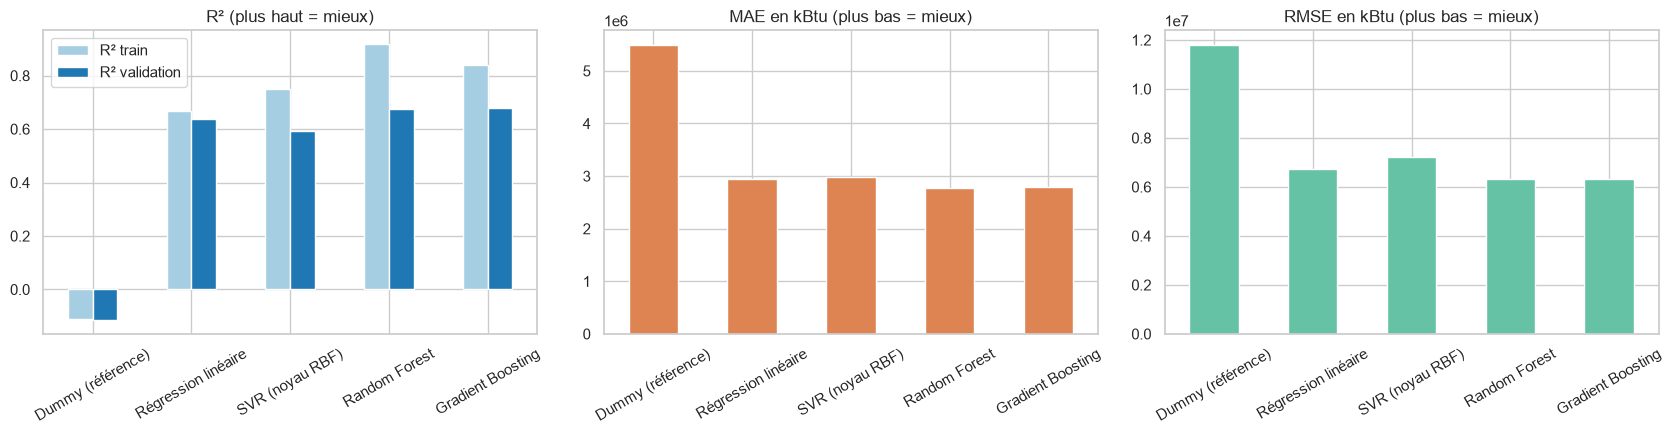

In [111]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

results[["R² train", "R² validation"]].plot.bar(ax=axes[0], rot=30, color=["#a6cee3", "#1f78b4"])
axes[0].set_title("R² (plus haut = mieux)")

results["MAE validation"].plot.bar(ax=axes[1], rot=30, color="#dd8452")
axes[1].set_title("MAE en kBtu (plus bas = mieux)")

results["RMSE validation"].plot.bar(ax=axes[2], rot=30, color="#66c2a5")
axes[2].set_title("RMSE en kBtu (plus bas = mieux)")

for ax in axes:
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

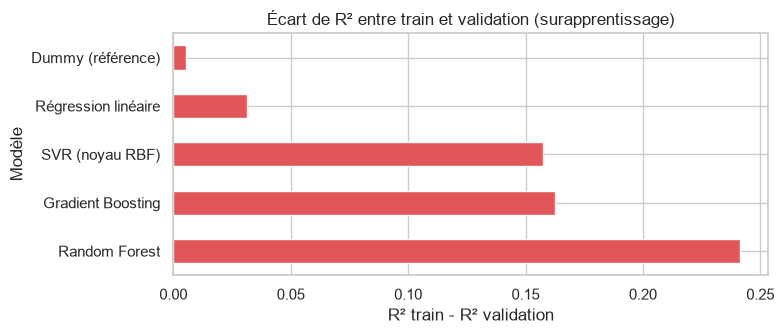

In [112]:
overfit = results["Écart R² (train - val.)"].sort_values(ascending=False)
overfit.plot.barh(figsize=(8, 3.5), color="#e15759")
plt.title("Écart de R² entre train et validation (surapprentissage)")
plt.xlabel("R² train - R² validation")
plt.tight_layout(); plt.show()

### Lecture des résultats

- **Dummy** : plancher de performance (R² ≈ −0,12 en validation). Tout modèle qui fait mieux a un vrai pouvoir prédictif.
- **Régression linéaire** : déjà solide (R² validation ≈ 0,64, MAE ≈ 2,95 M, RMSE ≈ 6,74 M), avec très peu de surapprentissage (écart train/validation ≈ 0,03).
- **SVR** : en retrait (R² validation ≈ 0,59, MAE ≈ 2,99 M, RMSE ≈ 7,21 M), avec un écart train/validation de ≈ 0,16.
- **Random Forest** : R² validation ≈ 0,676, MAE ≈ 2,77 M, RMSE ≈ 6,34 M, mais **le plus fort surapprentissage** (R² train ≈ 0,92, écart ≈ 0,24).
- **Gradient Boosting** : R² validation ≈ 0,678, MAE ≈ 2,79 M, RMSE ≈ 6,33 M, surapprentissage intermédiaire (écart ≈ 0,16).

**Random Forest et Gradient Boosting sont à égalité, devant la régression linéaire** : R² de validation de 0,68 contre 0,64, RMSE de 6,3 M contre 6,7 M. Cet avantage est du même ordre que la variabilité d'un pli à l'autre (écart-type du R² de 0,057 à 0,062) : il n'est pas tranché. Le SVR est le seul nettement en retrait.

**Sens métier** : en validation, une MAE d'environ 2,8 à 3,0 millions de kBtu correspond à une erreur moyenne d'environ **0,8 à 0,9 GWh par an** (1 kBtu ≈ 0,293 kWh). Elle est du même ordre que la consommation médiane du train (≈ 2,7 M kBtu), car les très gros bâtiments pèsent beaucoup dans la MAE.

**Choix pour la suite** : on retient le **Gradient Boosting**, non parce qu'il est nettement meilleur (il est à égalité avec la Random Forest, qui surapprend davantage), mais parce qu'il a plusieurs hyperparamètres à optimiser (profondeur, taux d'apprentissage, nombre d'arbres), contrairement à la régression linéaire. La question est de savoir si un réglage fin lui permet de dépasser nettement son résultat par défaut.


In [113]:
# --- Test d'ablation : chaque groupe de variables apporte-t-il quelque chose ? ---
# make_model (script/modeling.py) accepte directement la liste de variables numériques à garder.
floors_group = ["NumberofFloors", "GFAPerFloor", "IsHighRise"]   # dérivées des étages
without = lambda drop: [c for c in numeric_features if c not in drop]

scenarios = {
    "Référence (toutes les variables)": numeric_features,
    "- NumberofBuildings": without(["NumberofBuildings"]),
    "- Étages (3 variables)": without(floors_group),
    "- Les deux": without(floors_group + ["NumberofBuildings"]),
}

rows, r2_ref = [], None
for name, cols in scenarios.items():
    res = cross_validate(
        make_model(GradientBoostingRegressor(random_state=RANDOM_STATE), num_cols=cols),
        X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1,
    )
    r2 = res["test_r2"]
    r2_ref = r2 if r2_ref is None else r2_ref
    rows.append({
        "Scénario": name,
        "R² validation": r2.mean(),
        "Δ R² vs référence": (r2 - r2_ref).mean(),
        "Écart-type du Δ (plis)": (r2 - r2_ref).std(),
        "RMSE validation (kBtu)": -res["test_rmse"].mean(),
    })

display(pd.DataFrame(rows).set_index("Scénario").round(3))

,R² validation,Δ R² vs référence,Écart-type du Δ (plis),RMSE validation (kBtu)
Scénario,,,,
Référence (toutes les variables),0.678,0.000,0.000,6326037.405
- NumberofBuildings,0.682,0.004,0.009,6282000.403
- Étages (3 variables),0.685,0.006,0.008,6265016.826
- Les deux,0.688,0.010,0.010,6225238.673


**Lecture de l'ablation** : retirer `NumberofBuildings` change le R² de validation de +0,004 (± 0,009 selon les plis), retirer les trois variables liées aux étages de +0,006 (± 0,008), et les deux ensemble de +0,010 (± 0,010). Chaque variation est de l'ordre de l'écart-type entre plis : ces variables n'apportent **pas d'information mesurable**, et leur retrait ne fait pas perdre de performance. On les garde pour ne pas ajuster la sélection de variables sur du bruit, mais on pourrait les retirer sans dommage pour simplifier le modèle.


# Optimisation et interprétation du modèle

**Modèle retenu en mission 4** : Gradient Boosting.

Démarche :
1. **Test de la grille** sur quelques combinaisons, pour vérifier que le code tourne.
2. **GridSearchCV** sur au moins 3 hyperparamètres (grille de 100 à 500 combinaisons maximum).
3. **Évaluation finale** sur le jeu de test, resté vierge jusqu'ici.
4. **Importance des features**, seulement une fois l'optimisation terminée.

In [114]:
import time
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

base_model = make_model(GradientBoostingRegressor(random_state=RANDOM_STATE))

# Les noms de paramètres suivent le chemin : TransformedTargetRegressor -> Pipeline -> étape "model"
small_grid = {
    "regressor__model__n_estimators": [100, 200],
    "regressor__model__learning_rate": [0.05, 0.1],
    "regressor__model__max_depth": [2, 3, 4],
}

t0 = time.time()
small_search = GridSearchCV(base_model, small_grid, cv=cv,
                            scoring="neg_root_mean_squared_error", n_jobs=-1)
small_search.fit(X_train, y_train)
print(f"Test réussi : 12 combinaisons en {time.time() - t0:.0f} s")
print("Meilleurs paramètres (petit test) :", small_search.best_params_)

Test réussi : 12 combinaisons en 7 s
Meilleurs paramètres (petit test) : {'regressor__model__learning_rate': 0.1, 'regressor__model__max_depth': 4, 'regressor__model__n_estimators': 200}


In [115]:
param_grid = {
    "regressor__model__n_estimators": [100, 200, 300, 400],
    "regressor__model__learning_rate": [0.05, 0.1, 0.15],
    "regressor__model__max_depth": [1, 2, 3],
    "regressor__model__min_samples_leaf": [5, 10, 20],
}

n_combos = int(np.prod([len(v) for v in param_grid.values()]))
print(f"{n_combos} combinaisons x {cv.get_n_splits()} plis = {n_combos * cv.get_n_splits()} entraînements")
assert n_combos <= 500, "Grille trop grande : réduire le nombre de combinaisons"

t0 = time.time()
grid = GridSearchCV(
    base_model, param_grid, cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1, return_train_score=True,
)
grid.fit(X_train, y_train)
print(f"Terminé en {(time.time() - t0) / 60:.1f} min")

best_model = grid.best_estimator_
print("Meilleurs hyperparamètres :", grid.best_params_)
print(f"Meilleur RMSE (validation croisée) : {-grid.best_score_:,.0f} kBtu")

108 combinaisons x 5 plis = 540 entraînements
Terminé en 1.0 min
Meilleurs hyperparamètres : {'regressor__model__learning_rate': 0.15, 'regressor__model__max_depth': 3, 'regressor__model__min_samples_leaf': 5, 'regressor__model__n_estimators': 100}
Meilleur RMSE (validation croisée) : 6,017,986 kBtu


**Remarque** : la meilleure combinaison de la première grille est `n_estimators = 100`, `learning_rate = 0,15`, `max_depth = 3` et `min_samples_leaf = 5`, pour un RMSE de validation croisée de **6,02 M kBtu** (6,33 M pour le modèle par défaut, soit −5 %). Ses **quatre valeurs sont aux bords de la grille** : 100 est le minimum de `n_estimators`, 0,15 le maximum de `learning_rate`, 3 le maximum de `max_depth` et 5 le minimum de `min_samples_leaf`. L'optimum n'est donc pas encadré.

On explore une seconde grille, tournée vers des modèles plus lents et plus nombreux (200 à 800 arbres, taux d'apprentissage de 0,02 à 0,1, profondeur de 2 à 4). Elle ne fait **pas mieux** : meilleur RMSE de 6,08 M (`n_estimators = 600`, `learning_rate = 0,05`, `max_depth = 2`, `min_samples_leaf = 5`), et ses dix meilleures combinaisons sont toutes entre 6,08 M et 6,10 M : un plateau. Cette seconde grille n'est pas une extension de la première (elle n'inclut pas la combinaison gagnante de la première, 100 arbres et taux 0,15) : elle montre seulement qu'un réglage lent et profond n'apporte rien de plus. Le code retient automatiquement le modèle au meilleur RMSE de validation croisée, ici celui de la **première grille**. L'écart entre les réglages (≈ 1 %) est faible face à la variabilité entre plis vue plus haut : on ne cherche pas plus loin. Le tableau ci-dessous donne les dix meilleures combinaisons de la seconde grille.


In [68]:
param_grid_2 = {
    "regressor__model__n_estimators": [200, 400, 600, 800],
    "regressor__model__learning_rate": [0.02, 0.03, 0.05, 0.1],
    "regressor__model__max_depth": [2, 3, 4],
    "regressor__model__min_samples_leaf": [5, 10, 20],
}
n_combos = int(np.prod([len(v) for v in param_grid_2.values()]))
print(f"{n_combos} combinaisons x {cv.get_n_splits()} plis = {n_combos * cv.get_n_splits()} entraînements")
assert n_combos <= 500

grid_2 = GridSearchCV(base_model, param_grid_2, cv=cv, scoring="neg_root_mean_squared_error",
                      n_jobs=-1, return_train_score=True)
grid_2.fit(X_train, y_train)
print("Meilleurs hyperparamètres :", grid_2.best_params_)
print(f"Meilleur RMSE (validation croisée) : {-grid_2.best_score_:,.0f} kBtu "
      f"(contre {-grid.best_score_:,.0f} pour la première grille)")

# Modèle final = meilleure combinaison des deux grilles (même critère : RMSE en validation croisée)
best_model = grid_2.best_estimator_ if -grid_2.best_score_ < -grid.best_score_ else grid.best_estimator_
print("Modèle retenu pour l'évaluation finale :",
      "grille 2" if best_model is grid_2.best_estimator_ else "grille 1")


144 combinaisons x 5 plis = 720 entraînements
Meilleurs hyperparamètres : {'regressor__model__learning_rate': 0.05, 'regressor__model__max_depth': 2, 'regressor__model__min_samples_leaf': 5, 'regressor__model__n_estimators': 600}
Meilleur RMSE (validation croisée) : 6,076,498 kBtu (contre 6,017,986 pour la première grille)
Modèle retenu pour l'évaluation finale : grille 1


In [69]:
# Dix meilleures combinaisons de la grille 2 (la grille 1 est résumée dans le texte)
cv_res = pd.DataFrame(grid_2.cv_results_)
cols = ["param_regressor__model__n_estimators", "param_regressor__model__learning_rate",
        "param_regressor__model__max_depth", "param_regressor__model__min_samples_leaf",
        "mean_train_score", "mean_test_score"]
top = cv_res.sort_values("rank_test_score")[cols].head(10).copy()
top.columns = ["n_estimators", "learning_rate", "max_depth", "min_samples_leaf", "RMSE train", "RMSE validation"]
top[["RMSE train", "RMSE validation"]] = -top[["RMSE train", "RMSE validation"]]
display(top.round(3))

,n_estimators,learning_rate,max_depth,min_samples_leaf,RMSE train,RMSE validation
74,600,0.05,2,5,4510017.206,6076498.201
61,400,0.03,4,5,3702759.803,6077161.398
85,400,0.05,3,5,3892503.261,6077200.205
105,400,0.05,4,20,4266066.434,6078767.797
50,600,0.03,3,5,4029508.994,6084372.904
15,800,0.02,3,5,4184287.908,6087398.084
109,400,0.10,2,5,4168323.938,6094866.435
26,600,0.02,4,5,3721171.203,6096602.008
75,800,0.05,2,5,4192377.124,6100791.945
106,600,0.05,4,20,3783226.722,6101578.367


In [70]:
def evaluate(model, X_tr, y_tr, X_te, y_te):
    p_tr, p_te = model.predict(X_tr), model.predict(X_te)
    return {
        "R² train": r2_score(y_tr, p_tr), "R² test": r2_score(y_te, p_te),
        "MAE train": mean_absolute_error(y_tr, p_tr), "MAE test": mean_absolute_error(y_te, p_te),
        "RMSE train": np.sqrt(mean_squared_error(y_tr, p_tr)),
        "RMSE test": np.sqrt(mean_squared_error(y_te, p_te)),
    }

# Comparaison avec le même modèle SANS optimisation (paramètres par défaut)
default_model = make_model(GradientBoostingRegressor(random_state=RANDOM_STATE)).fit(X_train, y_train)

final = pd.DataFrame({
    "Gradient Boosting par défaut": evaluate(default_model, X_train, y_train, X_test, y_test),
    "Gradient Boosting optimisé": evaluate(best_model, X_train, y_train, X_test, y_test),
}).T
display(final.round(3))

,R² train,R² test,MAE train,MAE test,RMSE train,RMSE test
Gradient Boosting par défaut,0.833,0.641,2124004.025,2392983.808,4647487.136,5239639.770
Gradient Boosting optimisé,0.864,0.645,1892225.494,2416027.098,4190210.767,5211614.168


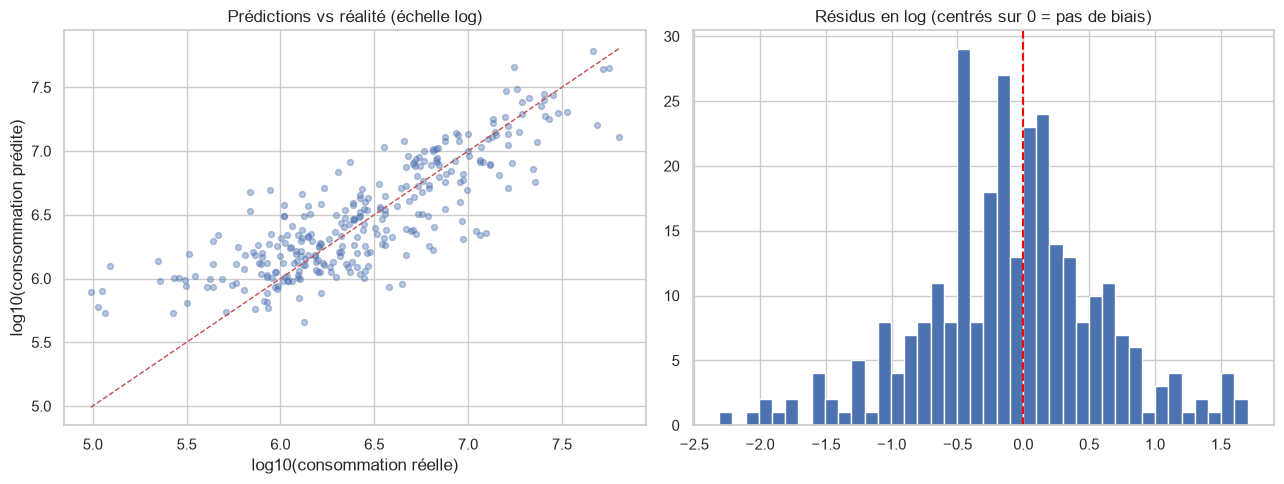

Erreur relative médiane : 41%
Bâtiments prédits à moins de 50 % d'erreur : 57%


In [71]:
pred_test = best_model.predict(X_test)
residuals_log = np.log1p(y_test) - np.log1p(np.clip(pred_test, 0, None))
rel_err = np.abs(pred_test - y_test) / y_test

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(np.log10(y_test), np.log10(np.clip(pred_test, 1, None)), alpha=0.4, s=18)
lims = [np.log10(y_test.min()), np.log10(y_test.max())]
axes[0].plot(lims, lims, "r--", lw=1)
axes[0].set_xlabel("log10(consommation réelle)")
axes[0].set_ylabel("log10(consommation prédite)")
axes[0].set_title("Prédictions vs réalité (échelle log)")

axes[1].hist(residuals_log, bins=40, color="#4c72b0", edgecolor="white")
axes[1].axvline(0, color="red", ls="--")
axes[1].set_title("Résidus en log (centrés sur 0 = pas de biais)")
plt.tight_layout(); plt.show()

print(f"Erreur relative médiane : {rel_err.median():.0%}")
print(f"Bâtiments prédits à moins de 50 % d'erreur : {(rel_err < 0.5).mean():.0%}")

**Lecture** :
- L'optimisation améliore la **validation croisée**, mais **pas le jeu de test** :
  - **En validation croisée** : le RMSE passe de **6,33 M** (modèle par défaut) à **6,02 M kBtu** (première grille, soit −5 %).
  - **Sur le jeu de test** : le R² reste à **0,64** (0,641 contre 0,645), la MAE passe de **2,39 M à 2,42 M kBtu** et le RMSE de 5,24 M à 5,21 M. Aucun gain mesurable.
- L'écart de R² entre entraînement et test **augmente** (**0,192** avant, **0,219** après optimisation) : le modèle optimisé ajuste mieux le train (RMSE de 4,2 M contre 4,6 M) sans mieux généraliser, signe d'un surapprentissage un peu plus fort.
- **Interprétation prudente** : le gain en validation croisée est faible et peut en partie venir de la sélection sur les scores de validation. Avec un jeu de test de 295 bâtiments, des écarts de cet ordre sont de toute façon dans le bruit. Le Gradient Boosting par défaut est déjà proche de ce que ces variables permettent.
- L'erreur relative médiane est de **41 %**, et **57 %** des bâtiments sont prédits avec moins de 50 % d'erreur.
- **Limite structurelle** : ce plafond de performance provient avant tout des variables disponibles (absence de données d'occupation réelle, d'horaires d'ouverture ou d'équipements techniques), et non d'un défaut de réglage des hyperparamètres.


,importance native
LogGFABuilding,0.662
LargestUseFamily,0.136
PrimaryPropertyType,0.077
BuildingAge,0.028
ParkingShare,0.023
DistDowntownKm,0.016
LargestUseShare,0.015
SecondUseShare,0.012
GFAPerFloor,0.009
NumUseTypes,0.008


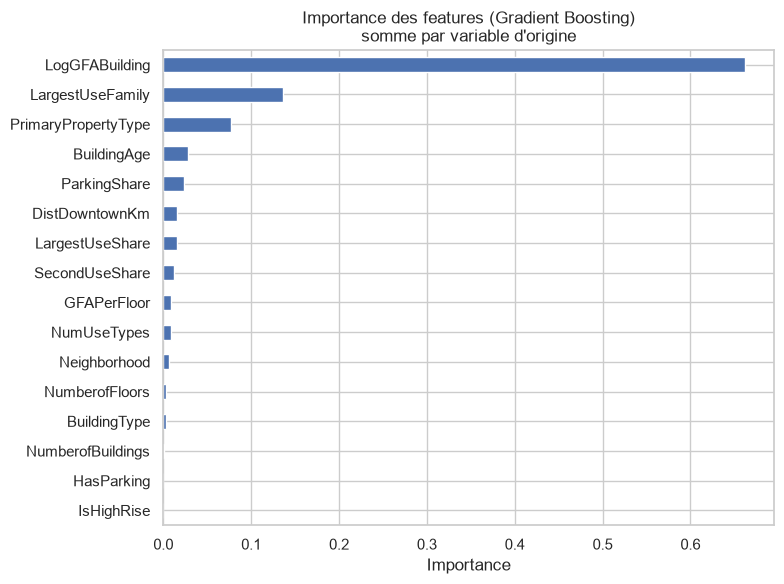

In [72]:
gb_pipeline = best_model.regressor_                 # Pipeline(prétraitement -> modèle)
gb = gb_pipeline.named_steps["model"]
feature_names = gb_pipeline.named_steps["prep"].get_feature_names_out()

imp = pd.Series(gb.feature_importances_, index=feature_names)

def origin(col):
    """Regroupe les colonnes OneHot sous le nom de la variable d'origine."""
    col = col.split("__", 1)[1]
    for c in categorical_features:
        if col.startswith(c + "_"):
            return c
    return col

imp_grouped = imp.groupby(origin).sum().sort_values()
display(imp_grouped.sort_values(ascending=False).round(3).to_frame("importance native"))

plt.figure(figsize=(8, 6))
imp_grouped.plot.barh(color="#4c72b0")
plt.title("Importance des features (Gradient Boosting)\nsomme par variable d'origine")
plt.xlabel("Importance")
plt.tight_layout(); plt.show()

,mean,std
LogGFABuilding,1.210,0.195
LargestUseFamily,0.136,0.042
LargestUseShare,0.098,0.030
PrimaryPropertyType,0.084,0.036
NumberofFloors,0.049,0.012
NumUseTypes,0.017,0.013
ParkingShare,0.016,0.017
NumberofBuildings,0.001,0.000
IsHighRise,0.000,0.000
HasParking,0.000,0.000


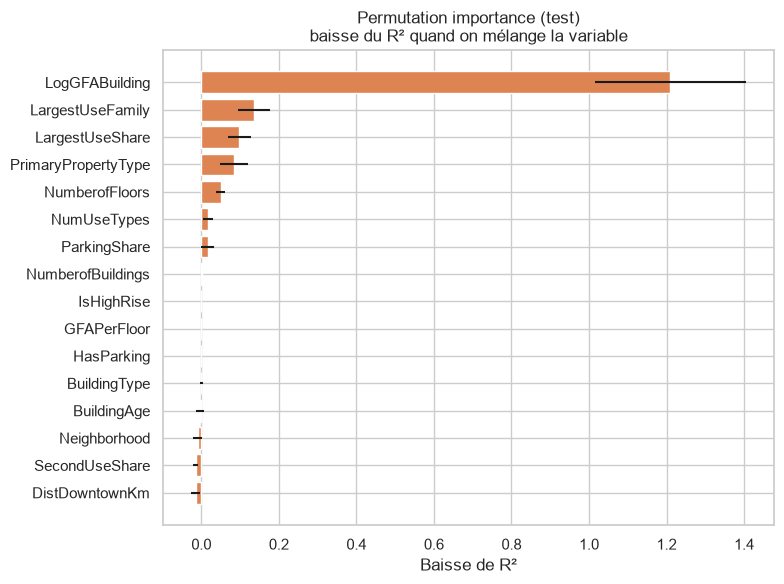

In [73]:
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=10, random_state=RANDOM_STATE, scoring="r2", n_jobs=-1,
)
perm_imp = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                        index=X_test.columns).sort_values("mean")

display(perm_imp.sort_values("mean", ascending=False).round(3))

plt.figure(figsize=(8, 6))
plt.barh(perm_imp.index, perm_imp["mean"], xerr=perm_imp["std"], color="#dd8452")
plt.title("Permutation importance (test)\nbaisse du R² quand on mélange la variable")
plt.xlabel("Baisse de R²")
plt.tight_layout(); plt.show()

### Interprétation

- **`LogGFABuilding` domine nettement** : environ 66 % de l'importance native et, de loin, la plus forte baisse de R² en permutation (≈ 1,21, soit plus que le R² du modèle : le R² est mesuré en kBtu, donc mélanger la surface crée des erreurs énormes sur les gros bâtiments). Le modèle estime d'abord la consommation à partir de la **taille** du bâtiment.
- **L'usage** (`LargestUseFamily` et `PrimaryPropertyType`) représente environ 21 % de l'importance native (≈ 14 % et ≈ 8 %). En permutation, `LargestUseFamily` arrive en deuxième position (≈ 0,14) devant `PrimaryPropertyType` (≈ 0,08).
- **`LargestUseShare`** est faible en importance native (≈ 0,015) mais 3ᵉ en permutation (≈ 0,10) : la part de l'usage dominant semble utile au modèle, à confirmer car les deux méthodes divergent.
- **`NumberofFloors`** (≈ 0,05 en permutation, ≈ 0,004 en natif), **`NumUseTypes`** (≈ 0,017) et **`ParkingShare`** (≈ 0,016) ont un effet faible. **`BuildingAge`** pèse un peu en importance native (≈ 0,03) mais pas en permutation (≈ −0,004).
- **Quasi nuls ou négatifs en permutation** : `NumberofBuildings` (≈ 0,001), `BuildingType` (≈ 0,000), `BuildingAge` (≈ −0,004), `Neighborhood` (≈ −0,009), `SecondUseShare` (≈ −0,014) et `DistDowntownKm` (≈ −0,015). Le modèle n'en tire pas d'information fiable.
- **`HasParking`** a une importance nulle : il est redondant avec `ParkingShare`.

⚠️ **Artefact à connaître** : `GFAPerFloor` et `IsHighRise` ont une importance par permutation de **exactement 0**. Ce n'est pas un résultat : le transformateur `FloorsImputer` recalcule ces deux colonnes à partir de `NumberofFloors` et de `LogGFABuilding`, donc mélanger les colonnes brutes ne change aucune prédiction. On ne peut rien conclure de la permutation pour ces deux variables (leur importance native est de ≈ 0,009 et 0).

⚠️ Les deux méthodes ne donnent pas le même classement : l'importance native se répartit entre variables corrélées, alors que la permutation mesure l'effet sur la performance. De plus, `LargestUseFamily` et `PrimaryPropertyType` sont **liées** (la famille est dérivée du plus grand usage, qui détermine en grande partie le type principal) : leur importance se partage entre les deux.

**Sens métier** : pour estimer la consommation d'un bâtiment non relevé, la **surface** est la donnée essentielle, puis son **usage**. La localisation et l'âge jouent un rôle mineur.


### Limites

- Précision modérée : R² ≈ 0,64 sur le test. Sur le test, la MAE est d'environ 2,4 millions de kBtu (≈ 0,7 GWh par an) ; en validation croisée, les modèles ont une MAE de 2,8 à 3,0 M (≈ 0,8 à 0,9 GWh). L'erreur relative médiane est de 41 %.
- L'optimisation des hyperparamètres n'améliore pas la performance sur le test (voir plus haut) : la précision est limitée par les variables disponibles.
- Les très gros sites sont peu représentés : les hôpitaux ne comptent que 4 bâtiments dans les données conservées, et les universités 19. Le modèle n'est pas fiable pour ces cas.
- Une seule année de données (2016), et pas de variables d'occupation ni d'équipements.
- Jeu de test de 295 bâtiments seulement : les métriques de test varient d'un tirage à l'autre (voir la double cible, où elles ne classent pas les modèles comme la validation croisée).
- Les métriques (R², MAE, RMSE) sont exprimées en kBtu : elles sont dominées par les plus gros bâtiments, alors que le modèle apprend sur le log de la consommation.
- Les seuils de nettoyage sont calculés sur l'ensemble du jeu avant la séparation train/test (effet marginal, quelques dizaines de lignes).
- Piste d'amélioration : essayer d'autres familles de modèles (XGBoost, LightGBM) ou enrichir les données.


---
# Extension : Modélisation sur la double cible (`SiteEnergyUse(kBtu)` et `TotalGHGEmissions`)

Conformément à l'objectif de neutralité carbone de Seattle, nous dupliquons ici la démarche de modélisation supervisée sur les **émissions totales de gaz à effet de serre (`TotalGHGEmissions`)** afin de comparer les performances et les facteurs d'influence avec la consommation énergétique (`SiteEnergyUse(kBtu)`).

**Points d'attention spécifiques à `TotalGHGEmissions`** :
- La cible présente également une forte asymétrie (*skewness* élevé), justifiant l'utilisation de `TransformedTargetRegressor` avec `np.log1p` / `np.expm1`.
- Certaines valeurs sont nulles ou légèrement négatives (ex. : le *Bullitt Center* à −0,8 tonne équivalent $CO_2$ grâce à une production nette positive). On filtre `TotalGHGEmissions > 0` afin de comparer les deux cibles sur exactement les mêmes bâtiments (la transformation `log1p` accepterait ces valeurs). Ce filtre ne retire qu'**1 bâtiment** : le périmètre est de **1 471 bâtiments**, contre 1 472 dans la partie principale. Les chiffres obtenus ici pour la consommation d'énergie diffèrent donc légèrement de ceux de la partie principale (autre découpage train/test).

In [74]:
# Définition des deux cibles à comparer à périmètre constant
TARGETS = ["SiteEnergyUse(kBtu)", "TotalGHGEmissions"]

# Filtrage des valeurs strictement positives sur les deux cibles (gestion des bâtiments à bilan carbone négatif/nul)
mask_valid_targets = (data["SiteEnergyUse(kBtu)"] > 0) & (data["TotalGHGEmissions"] > 0)
data_dual = data[mask_valid_targets].copy()

X_dual = data_dual[numeric_features + categorical_features]

# Définition des modèles à comparer
dual_models = {
    "Dummy (référence)": DummyRegressor(strategy="mean"),
    "Régression linéaire": LinearRegression(),
    "SVR (noyau RBF)": SVR(),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

dual_results = []

for target_col in TARGETS:
    y_target = data_dual[target_col]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_dual, y_target, test_size=0.2, random_state=RANDOM_STATE
    )
    
    for model_name, est in dual_models.items():
        res = evaluate_model(model_name, est, X=X_tr, y=y_tr)
        res["Cible"] = target_col
        
        # Évaluation complémentaire sur le jeu de test
        fitted_pipe = make_model(est).fit(X_tr, y_tr)
        preds_te = fitted_pipe.predict(X_te)
        res["R² test"] = r2_score(y_te, preds_te)
        res["MAE test"] = mean_absolute_error(y_te, preds_te)
        dual_results.append(res)

df_dual_summary = pd.DataFrame(dual_results)[
    ["Cible", "Modèle", "R² train", "R² validation", "R² test", "MAE validation", "MAE test"]
]
display(df_dual_summary.round(3))

,Cible,Modèle,R² train,R² validation,R² test,MAE validation,MAE test
0,SiteEnergyUse(kBtu),Dummy (référence),-0.109,-0.111,-0.112,5431121.461,4839180.113
1,SiteEnergyUse(kBtu),Régression linéaire,0.674,0.624,0.653,2906827.180,2561607.494
2,SiteEnergyUse(kBtu),SVR (noyau RBF),0.762,0.572,0.623,2977877.776,2658212.173
3,SiteEnergyUse(kBtu),Random Forest,0.922,0.678,0.593,2817394.813,2658048.297
4,SiteEnergyUse(kBtu),Gradient Boosting,0.840,0.695,0.592,2731757.657,2649256.531
5,TotalGHGEmissions,Dummy (référence),-0.103,-0.107,-0.090,113.239,111.384
6,TotalGHGEmissions,Régression linéaire,0.537,0.451,0.487,79.210,84.369
7,TotalGHGEmissions,SVR (noyau RBF),0.539,0.333,0.410,83.743,81.453
8,TotalGHGEmissions,Random Forest,0.857,0.463,0.334,81.357,86.229
9,TotalGHGEmissions,Gradient Boosting,0.704,0.463,0.442,79.684,83.210


### Lecture des résultats de la double cible

- **Consommation d'énergie** : R² de validation de ≈ 0,62 (régression linéaire), ≈ 0,68 (Random Forest) et ≈ 0,70 (Gradient Boosting) ; le Gradient Boosting atteint un R² de test de ≈ 0,59.
- **Émissions de CO₂** : nettement moins bien prédites en validation, avec un R² de **0,33 à 0,47** (≈ 0,45 pour la linéaire, ≈ 0,33 pour le SVR, ≈ 0,47 pour la Random Forest, ≈ 0,46 pour le Gradient Boosting), contre 0,57 à 0,70 pour l'énergie.
- ⚠️ **Les scores de test ne classent pas les modèles comme la validation croisée** : pour l'énergie, la Random Forest est à 0,68 en validation mais 0,59 sur le test, alors que la régression linéaire passe de 0,62 à 0,65 ; pour le CO₂, la Random Forest passe de 0,47 à 0,33. Avec 295 bâtiments, quelques gros émetteurs suffisent à faire varier le résultat. On s'appuie donc sur la validation croisée.
- La Random Forest surapprend fortement sur les deux cibles (R² train ≈ 0,92 pour l'énergie, ≈ 0,86 pour le CO₂).
- Les **MAE ne sont pas comparables entre les deux cibles** (kBtu contre tonnes d'équivalent CO₂) : seul le R² permet de comparer.
- **Facteurs d'influence** : pour les deux cibles, la surface domine (permutation ≈ 0,88 pour l'énergie, ≈ 0,59 pour le CO₂), suivie de la famille d'usage (≈ 0,12 et ≈ 0,22) puis du type principal (≈ 0,06 et ≈ 0,12). La surface pèse moins pour le CO₂ : l'usage y compte relativement plus.
- **Explication probable** : les émissions dépendent surtout du **mix énergétique** (gaz, vapeur) et non de l'énergie totale, car l'électricité à Seattle est fortement décarbonée (hydroélectricité). Aucune feature actuelle n'indique les sources d'énergie installées dans le bâtiment.
  - **Piste testée ci-dessous** : ajouter des indicateurs `HasGas` et `HasSteam`.
  - **Point de vigilance (*data leakage*)** : en production, ces variables ne doivent pas être déduites des relevés de compteurs (`NaturalGas(kBtu)`, `SteamUse(kBtu)`) qui constituent des factures énergétiques *a posteriori*, mais provenir d'un registre administratif de raccordement aux réseaux (gaz de ville ou vapeur urbaine).


In [75]:
# Test exploratoire : l'ajout d'indicateurs "gaz" et "vapeur" améliore-t-il la prédiction du CO2 ?
# ATTENTION : ces indicateurs sont déduits ici des relevés de compteurs, uniquement pour mesurer le potentiel.
# En production, il faudrait les tirer d'un registre de raccordement (voir plus haut).
from sklearn.ensemble import GradientBoostingRegressor

dd = data_dual.copy()
dd["HasGas"] = (df.loc[dd.index, "NaturalGas(kBtu)"].fillna(0) > 0).astype(int)
dd["HasSteam"] = (df.loc[dd.index, "SteamUse(kBtu)"].fillna(0) > 0).astype(int)
print(f"Périmètre : {len(dd)} bâtiments | avec gaz : {dd.HasGas.mean():.0%} | avec vapeur : {dd.HasSteam.mean():.0%}")

def make_co2_model(num_cols):
    return make_model(GradientBoostingRegressor(random_state=RANDOM_STATE), num_cols=num_cols)

with_gas = numeric_features + ["HasGas", "HasSteam"]
X_tr_g, _, y_tr_g, _ = train_test_split(dd[with_gas + categorical_features], dd["TotalGHGEmissions"],
                                        test_size=0.2, random_state=RANDOM_STATE)
r_base = cross_validate(make_co2_model(numeric_features), X_tr_g, y_tr_g, cv=cv, scoring="r2")["test_score"]
r_gas = cross_validate(make_co2_model(with_gas), X_tr_g, y_tr_g, cv=cv, scoring="r2")["test_score"]

gas_test = pd.DataFrame({"R² sans indicateurs": r_base, "R² avec HasGas + HasSteam": r_gas})
gas_test["Écart"] = gas_test.iloc[:, 1] - gas_test.iloc[:, 0]
gas_test.index = [f"pli {i + 1}" for i in range(len(gas_test))]
gas_test.loc["moyenne"] = gas_test.mean()
display(gas_test.round(3))
print(f"Écart moyen : {gas_test['Écart'].iloc[:-1].mean():+.3f} | écart-type entre plis : {gas_test['Écart'].iloc[:-1].std():.3f}")


Périmètre : 1471 bâtiments | avec gaz : 71% | avec vapeur : 7%


,R² sans indicateurs,R² avec HasGas + HasSteam,Écart
pli 1,0.536,0.558,0.022
pli 2,0.476,0.436,-0.040
pli 3,0.443,0.587,0.144
pli 4,0.407,0.352,-0.055
pli 5,0.451,0.412,-0.039
moyenne,0.463,0.469,0.006


Écart moyen : +0.006 | écart-type entre plis : 0.083


**Lecture du test** : en moyenne, les indicateurs de gaz et de vapeur font passer le R² de validation du Gradient Boosting de ≈ 0,463 à ≈ 0,469 (+ 0,006) pour le CO₂. L'écart varie fortement d'un pli à l'autre (de −0,055 à +0,144, écart-type ≈ 0,08) : le gain moyen est **quasi nul et noyé dans le bruit**, l'hypothèse n'est donc **pas confirmée** par ces données. Ces indicateurs sont ici déduits des relevés, uniquement pour estimer le potentiel ; même sans fuite, ils n'apporteraient pas de gain mesurable avec ce jeu.


Permutation importance (test) - SiteEnergyUse(kBtu)


,mean,std
LogGFABuilding,0.875,0.151
LargestUseFamily,0.123,0.034
PrimaryPropertyType,0.061,0.023
NumberofFloors,0.019,0.011
ParkingShare,0.013,0.010
BuildingAge,0.010,0.008
NumUseTypes,0.002,0.007
BuildingType,0.001,0.008


Permutation importance (test) - TotalGHGEmissions


,mean,std
LogGFABuilding,0.587,0.101
LargestUseFamily,0.215,0.072
PrimaryPropertyType,0.116,0.028
NumberofFloors,0.028,0.018
BuildingAge,0.024,0.011
ParkingShare,0.010,0.015
Neighborhood,0.007,0.008
NumberofBuildings,0.004,0.008


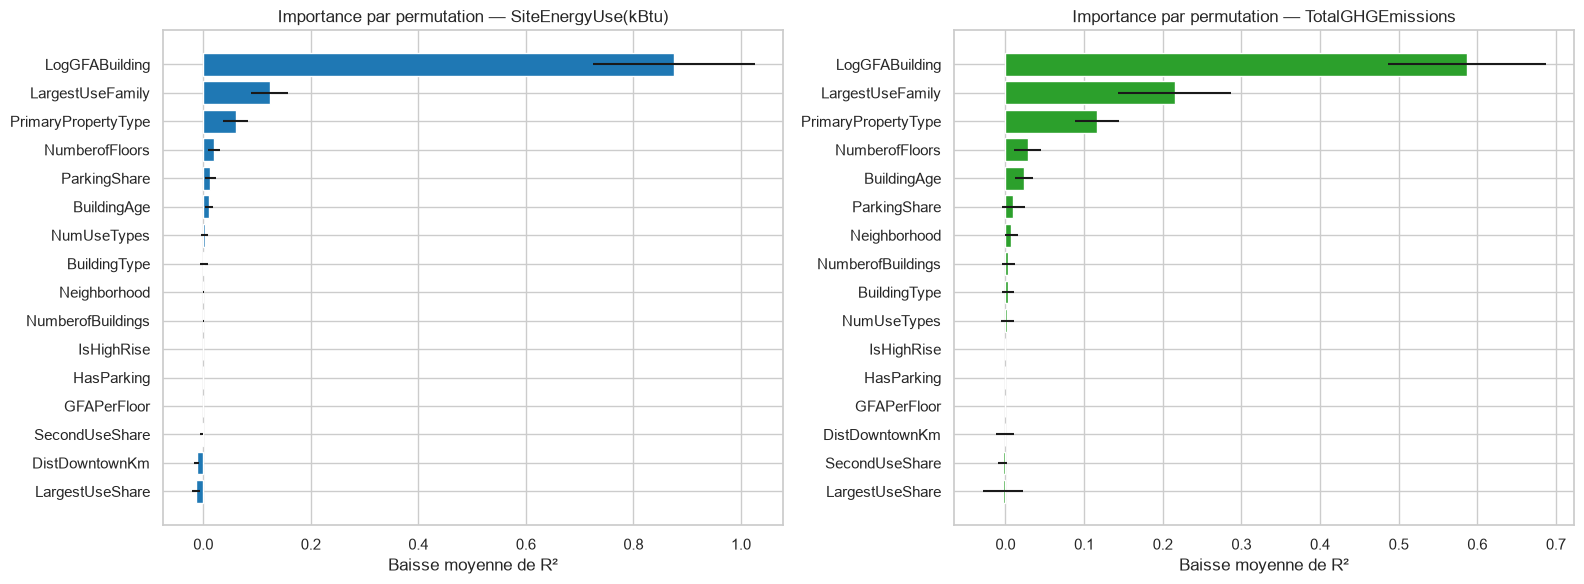

In [76]:
# Comparaison de l'importance des variables (Gradient Boosting) entre Énergie et Émissions de CO2
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, target_col in zip(axes, TARGETS):
    y_target = data_dual[target_col]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_dual, y_target, test_size=0.2, random_state=RANDOM_STATE
    )
    
    gb_dual = make_model(GradientBoostingRegressor(random_state=RANDOM_STATE))
    gb_dual.fit(X_tr, y_tr)
    
    perm_dual = permutation_importance(
        gb_dual, X_te, y_te, n_repeats=10, random_state=RANDOM_STATE, scoring="r2", n_jobs=-1
    )
    imp_df = pd.DataFrame({
        "mean": perm_dual.importances_mean,
        "std": perm_dual.importances_std
    }, index=X_te.columns).sort_values("mean")
    
    print(f"Permutation importance (test) - {target_col}")
    display(imp_df.sort_values("mean", ascending=False).round(3).head(8))
    ax.barh(imp_df.index, imp_df["mean"], xerr=imp_df["std"], color="#1f78b4" if target_col == "SiteEnergyUse(kBtu)" else "#2ca02c")
    ax.set_title(f"Importance par permutation — {target_col}")
    ax.set_xlabel("Baisse moyenne de R²")

plt.tight_layout()
plt.show()